# Heart Murmur Detection from Heart Sound Recordings for Screening in Low-Resource Settings

## 1. Introduction

### 1.1 Background and Use Case

This project extends my previous summative assignment, which classified heartbeat arrhythmias from single-lead ECG beats. That dataset was stored as rows of voltage values, so it behaved like a tabular dataset. This assignment asks for **non-tabular data**, and the natural next step in the same cardiac screening theme is **heart sound audio**: recordings made with a digital stethoscope.

The task is to decide, for one recording, whether a **heart murmur** is present. A murmur is an extra sound between the normal heart sounds, caused by turbulent blood flow, and it can be a sign of a structural heart problem. Listening for murmurs takes training, and trained cardiologists are scarce in many low-resource settings. A model that flags recordings with a likely murmur could help a nurse or community health worker decide who should be referred for a specialist assessment. It is a screening aid and not a diagnosis.

The data come from the **CirCor DigiScope Phonocardiogram Dataset**: heart sound recordings from children, taken at several standard auscultation sites on the chest (aortic AV, pulmonary PV, tricuspid TV and mitral MV), with a clinician's murmur label for each patient (Present, Absent or Unknown) and the sites where the murmur was heard.

### 1.2 What Changes Compared with Tabular Data

- Recordings have **different lengths**, but a CNN needs inputs of a fixed size, so each recording is cut into fixed windows.
- Raw audio is a long one-dimensional signal. It is converted to a **log-mel spectrogram** (frequency against time), which a convolutional network can process like an image.
- One patient contributes **several recordings**, and recordings from one child resemble each other. A random split would put the same child in training and test and overstate performance, so the split is made **by patient**. My ECG report found the same problem between random-beat and patient-wise splits.
- Murmurs are a minority class, so accuracy alone is misleading and the evaluation uses precision, recall, F1 and PR-AUC.

### 1.3 How This Notebook Connects to the Deployed Application

This notebook is the offline part of an ML pipeline. Its outputs are used directly by the rest of the project:

| Notebook output | Used by |
|---|---|
| `preprocessing.py` (written in Section 2.2) | the API, the upload and retraining code, and this notebook, so the features are identical everywhere |
| `models/murmur_cnn_v1.h5` and the decision threshold | the prediction API |
| small training and validation samples | the retraining code in the deployed app |
| demo recordings and result tables | the web UI and the load tests |

### 1.4 Notebook Outline

1. Introduction
2. Setup
3. Data Acquisition
4. Exploratory Data Analysis
5. Data Preprocessing
6. Visualizations of the Processed Data
7. Model Creation (three experiments)
8. Model Evaluation
9. Model Selection and Saving
10. Prediction Function (demo)
11. Retraining Demonstration
12. Conclusions

## 2. Setup

### 2.1 Dependencies and Reproducibility

The three experiments in Section 7 are only comparable if they are trained under the same conditions, so the random seed is fixed for Python, NumPy and TensorFlow, and the same split, class weights and callbacks logic are used throughout. GPU training in TensorFlow is not bit-for-bit repeatable, so a rerun can differ slightly. The model exported at the end of this notebook is the one used in the deployed application, and every number reported comes from the same run.

In [1]:
import os, glob, json, time, shutil, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import soundfile as sf
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from joblib import Parallel, delayed
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score, recall_score,
                             accuracy_score, log_loss, classification_report, confusion_matrix,
                             roc_curve, precision_recall_curve)
warnings.filterwarnings("ignore")

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

DATA_ROOT = "/kaggle/input/datasets/bjoernjostein/the-circor-digiscope-phonocardiogram-dataset-v2"
WORK = "/kaggle/working"
OUT_DIR = f"{WORK}/processed"       # preprocessed spectrograms
FIG_DIR = f"{WORK}/figures"         # figures used by the UI and the report
RES_DIR = f"{WORK}/results"         # result tables
MODELS_DIR = f"{WORK}/models"
for d in (OUT_DIR, FIG_DIR, RES_DIR, MODELS_DIR):
    os.makedirs(d, exist_ok=True)

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
print("TensorFlow", tf.__version__, "| GPUs:", [g.name for g in tf.config.list_physical_devices("GPU")])

TensorFlow 2.21.0 | GPUs: ['/physical_device:GPU:0', '/physical_device:GPU:1']


### 2.2 The Shared Preprocessing Module

All audio processing lives in one module, `preprocessing.py`. The notebook writes it to disk and imports it, and the same file is copied into the project's `src/` folder, so training, prediction and retraining cannot drift apart. Each step is explained in Section 5.2.

In [2]:
%%writefile preprocessing.py
"""Heart sound preprocessing. One module shared by the notebook, the API and retraining."""
import numpy as np
import librosa
from scipy.signal import butter, sosfiltfilt

SR = 4000                  # target sample rate (Hz)
LOW_HZ, HIGH_HZ = 25, 500  # band-pass range for heart sounds and murmurs
WIN_SEC = 5.0              # window length
HOP_SEC = 5.0              # hop between windows (non-overlapping)
MIN_SEC = 1.5              # recordings shorter than this are skipped
N_MELS, N_FFT, HOP_LENGTH = 64, 512, 128

_SOS = butter(4, [LOW_HZ, HIGH_HZ], btype="bandpass", fs=SR, output="sos")


def load_audio(path):
    y, _ = librosa.load(path, sr=SR, mono=True)
    return y.astype(np.float32)


def bandpass(y):
    return sosfiltfilt(_SOS, y).astype(np.float32)


def split_windows(y, max_windows=None):
    """Cut a recording into fixed-length windows. The last partial window is zero-padded
    only if it holds at least MIN_SEC of signal. Returns an array (n_windows, win_samples)."""
    win, hop, min_len = int(WIN_SEC * SR), int(HOP_SEC * SR), int(MIN_SEC * SR)
    if len(y) < min_len:
        return np.empty((0, win), dtype=np.float32)
    windows = []
    for start in range(0, len(y), hop):
        seg = y[start:start + win]
        if len(seg) < win:
            if len(seg) < min_len and windows:
                break
            seg = np.pad(seg, (0, win - len(seg)))
        windows.append(seg)
        if max_windows and len(windows) >= max_windows:
            break
    return np.stack(windows).astype(np.float32)


def to_logmel(window):
    """One window -> standardised log-mel spectrogram of shape (N_MELS, frames)."""
    m = librosa.feature.melspectrogram(
        y=window, sr=SR, n_fft=N_FFT, hop_length=HOP_LENGTH,
        n_mels=N_MELS, fmin=LOW_HZ, fmax=HIGH_HZ, power=2.0)
    db = librosa.power_to_db(m, ref=1.0, top_db=80.0)
    return ((db - db.mean()) / (db.std() + 1e-6)).astype(np.float32)


def wav_to_features(path, max_windows=None):
    """.wav path -> array (n_windows, N_MELS, frames, 1). Empty array if too short."""
    y = bandpass(load_audio(path))
    wins = split_windows(y, max_windows)
    if len(wins) == 0:
        return np.empty((0, N_MELS, 1 + int(WIN_SEC * SR) // HOP_LENGTH, 1), dtype=np.float32)
    return np.stack([to_logmel(w) for w in wins])[..., None]

Writing preprocessing.py


In [3]:
import preprocessing as P
print("sample rate", P.SR, "| band", P.LOW_HZ, "-", P.HIGH_HZ, "Hz | window", P.WIN_SEC, "s | mel bands", P.N_MELS)

sample rate 4000 | band 25 - 500 Hz | window 5.0 s | mel bands 64


## 3. Data Acquisition

### 3.1 Locating the Recordings

The dataset is attached to this Kaggle notebook as an input, so nothing needs to be downloaded. Recordings are .wav files named `<patient id>_<site>.wav` (for example `2530_AV.wav`), and a metadata table `training_data.csv` holds one row per patient.

In [4]:
wavs = sorted(glob.glob(os.path.join(DATA_ROOT, "**", "*.wav"), recursive=True))
print(len(wavs), "wav files found")
if not wavs:
    raise SystemExit("No .wav files under DATA_ROOT. Check the dataset path above.")
print("example paths:", [os.path.basename(p) for p in wavs[:4]])

3163 wav files found
example paths: ['13918_AV.wav', '13918_MV.wav', '13918_PV.wav', '13918_TV.wav']


### 3.2 The Metadata Table

In [5]:
meta_raw = pd.read_csv(os.path.join(DATA_ROOT, "training_data.csv"))
meta_raw.columns = [c.strip() for c in meta_raw.columns]
print("shape:", meta_raw.shape)
display(meta_raw.head())
print("\nMissing values per column:")
display(meta_raw.isna().sum().to_frame("missing").T)

shape: (942, 22)


,Patient ID,Locations,Age,Sex,Height,Weight,Pregnancy status,Murmur,Murmur locations,Most audible location,...,Systolic murmur grading,Systolic murmur pitch,Systolic murmur quality,Diastolic murmur timing,Diastolic murmur shape,Diastolic murmur grading,Diastolic murmur pitch,Diastolic murmur quality,Campaign,Additional ID
0,2530,AV+PV+TV+MV,Child,Female,98.0,15.9,False,Absent,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,CC2015,NaN
1,9979,AV+PV+TV+MV,Child,Female,103.0,13.1,False,Present,AV+MV+PV+TV,TV,...,III/VI,High,Harsh,NaN,NaN,NaN,NaN,NaN,CC2015,NaN
2,9983,AV+PV+TV+MV,Child,Male,115.0,19.1,False,Unknown,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,CC2015,NaN
3,13918,AV+PV+TV+MV,Child,Male,98.0,15.9,False,Present,TV,TV,...,I/VI,Low,Blowing,NaN,NaN,NaN,NaN,NaN,CC2015,NaN
4,14241,AV+PV+TV+MV,Child,Male,87.0,11.2,False,Present,AV+MV+PV+TV,PV,...,II/VI,Low,Harsh,NaN,NaN,NaN,NaN,NaN,CC2015,NaN



Missing values per column:


,Patient ID,Locations,Age,Sex,Height,Weight,Pregnancy status,Murmur,Murmur locations,Most audible location,...,Systolic murmur grading,Systolic murmur pitch,Systolic murmur quality,Diastolic murmur timing,Diastolic murmur shape,Diastolic murmur grading,Diastolic murmur pitch,Diastolic murmur quality,Campaign,Additional ID
missing,0,0,74,0,116,105,0,0,763,763,...,764,764,764,937,937,937,937,937,0,802


### 3.3 Which Columns the Model Uses

Only three columns matter for the pipeline: `Patient ID` (to group recordings and split by patient), `Murmur` (the label: Present, Absent or Unknown) and `Murmur locations` (the sites where the murmur was heard, used in the labelling rule in Section 5.1).

The other clinical columns (age, sex, height, weight, murmur grading, pitch, quality and so on) are used **only for exploration** in Section 4. They are never inputs to the model: the model must decide from the sound alone, and columns such as murmur grading and pitch exist only for patients who already have a murmur, so using them would leak the answer.

In [6]:
meta = meta_raw.rename(columns={"Patient ID": "patient_id", "Murmur": "murmur", "Murmur locations": "murmur_locs"})
print("patients in the table:", meta["patient_id"].nunique())

patients in the table: 942


## 4. Exploratory Data Analysis

Before any preprocessing or modelling, this section looks at what the data contain: how common murmurs are, who the patients are, how many recordings each patient has, how long and how loud the recordings are, and what a murmur looks like in the signal. The findings are collected at the end of the section and drive the preprocessing choices in Section 5.

### 4.1 Label Distribution (Patient Level)

The label is assigned to the patient, not to the recording. The chart shows how many patients fall into each class.

,patients,percent
murmur,,
Absent,695,73.8
Present,179,19.0
Unknown,68,7.2


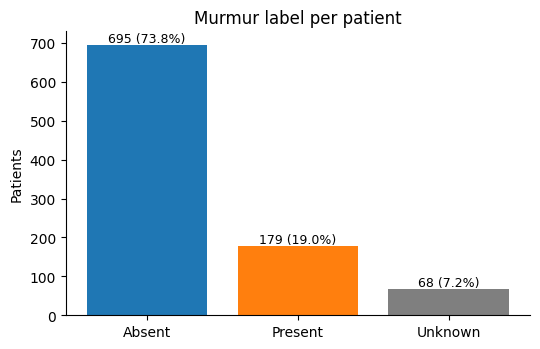

In [7]:
order = ["Absent", "Present", "Unknown"]
counts = meta["murmur"].value_counts().reindex(order).fillna(0).astype(int)
pct = (counts / counts.sum() * 100).round(1)
display(pd.DataFrame({"patients": counts, "percent": pct}))
fig, ax = plt.subplots(figsize=(5.5, 3.6))
ax.bar(counts.index, counts.values, color=["tab:blue", "tab:orange", "tab:gray"])
for i, (c, p) in enumerate(zip(counts.values, pct.values)):
    ax.text(i, c + counts.max() * 0.01, f"{c} ({p}%)", ha="center", fontsize=9)
ax.set_ylabel("Patients"); ax.set_title("Murmur label per patient")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/eda1_patient_labels.png", dpi=150); plt.show()

**Interpretation.** _To be written after the run._

<!-- interp:4.1 -->

### 4.2 Who Are the Patients? Age Group and Sex

These columns are not model inputs, but they show whether the murmur rate differs between groups, which affects how the results should be interpreted.

Age


murmur,Absent,Present,rate_pct
Age,,,
Adolescent,47,16,25.4
Child,450,119,20.9
Infant,121,37,23.4
Missing,67,5,6.9
Neonate,4,1,20.0
Young Adult,6,1,14.3


Sex


murmur,Absent,Present,rate_pct
Sex,,,
Female,355,92,20.6
Male,340,87,20.4


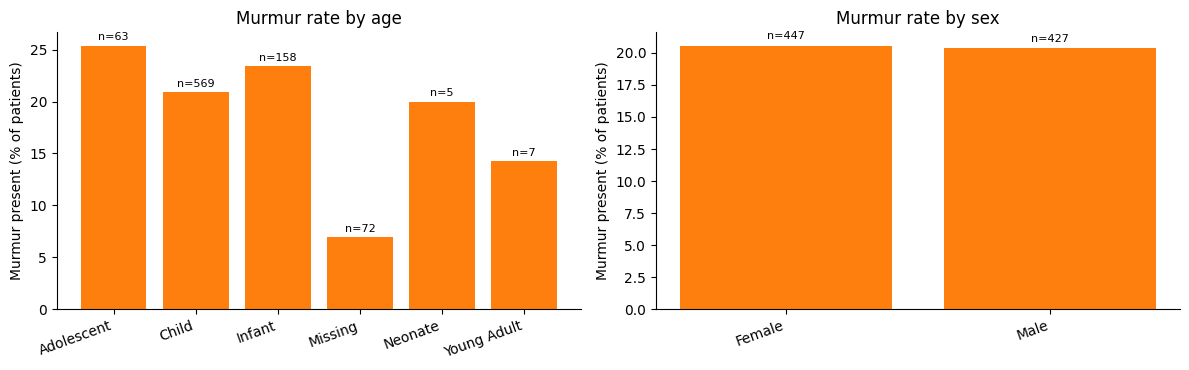

In [8]:
eda = meta.copy()
for col in ["Age", "Sex"]:
    eda[col] = eda[col].fillna("Missing")
eda = eda[eda["murmur"].isin(["Present", "Absent"])]
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, col in zip(axs, ["Age", "Sex"]):
    ct = pd.crosstab(eda[col], eda["murmur"])
    rate = (ct["Present"] / ct.sum(axis=1) * 100)
    ax.bar(ct.index.astype(str), rate.values, color="tab:orange")
    for i, (idx, n) in enumerate(ct.sum(axis=1).items()):
        ax.text(i, rate.loc[idx] + 0.5, f"n={n}", ha="center", fontsize=8)
    ax.set_ylabel("Murmur present (% of patients)"); ax.set_title(f"Murmur rate by {col.lower()}")
    plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
    print(col); display(ct.assign(rate_pct=rate.round(1)))
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/eda2_demographics.png", dpi=150); plt.show()

**Interpretation.** _To be written after the run._

<!-- interp:4.2 -->

### 4.3 Recording Inventory

Each patient has several recordings, one per auscultation site. This subsection builds the table of recordings (one row per .wav file) and checks that the files and the metadata match.

recordings: 3163 | patients with recordings: 942
patients in metadata without recordings: 0
patients with recordings but not in metadata: 0


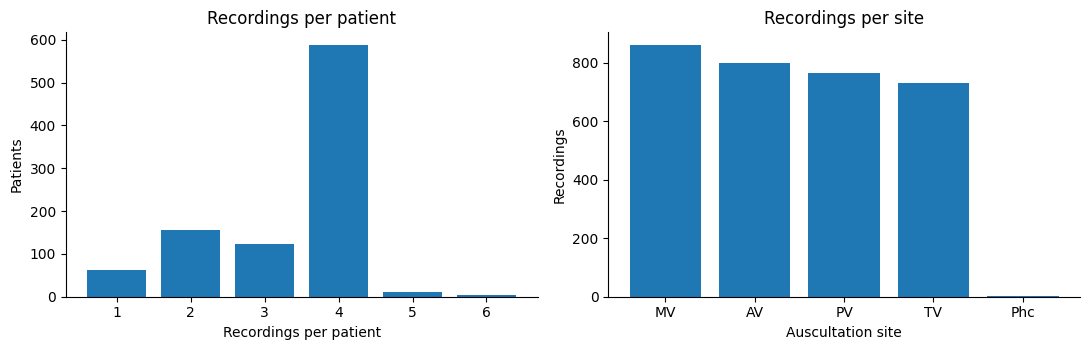

recordings per patient: mean 3.36, median 4, min 1, max 6


site,MV,AV,PV,TV,Phc
recordings,861,800,766,732,4


In [9]:
rows = []
for p in wavs:
    parts = os.path.splitext(os.path.basename(p))[0].split("_")
    if parts[0].isdigit() and len(parts) > 1:
        rows.append({"path": p, "patient_id": int(parts[0]), "site": parts[1]})
inv = pd.DataFrame(rows)
print("recordings:", len(inv), "| patients with recordings:", inv["patient_id"].nunique())
print("patients in metadata without recordings:", len(set(meta["patient_id"]) - set(inv["patient_id"])))
print("patients with recordings but not in metadata:", len(set(inv["patient_id"]) - set(meta["patient_id"])))

per_patient = inv.groupby("patient_id").size()
site_counts = inv["site"].value_counts()
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
vc = per_patient.value_counts().sort_index()
axs[0].bar(vc.index.astype(str), vc.values); axs[0].set_xlabel("Recordings per patient"); axs[0].set_ylabel("Patients")
axs[0].set_title("Recordings per patient")
axs[1].bar(site_counts.index, site_counts.values); axs[1].set_xlabel("Auscultation site"); axs[1].set_ylabel("Recordings")
axs[1].set_title("Recordings per site")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/eda3_inventory.png", dpi=150); plt.show()
print("recordings per patient: mean %.2f, median %d, min %d, max %d" % (per_patient.mean(), per_patient.median(), per_patient.min(), per_patient.max()))
display(site_counts.to_frame("recordings").T)

**Interpretation.** _To be written after the run._

<!-- interp:4.3 -->

### 4.4 Audio Properties: Sample Rate and Duration

The header of each file gives its sample rate and length without loading the audio, which is fast. These values decide how the recordings are standardised.

sample rates: {4000: 3163} | channels: {1: 3163}


,count,mean,std,min,25%,50%,75%,max
duration (s),3163.0,22.9,7.3,5.2,19.1,21.5,29.4,64.5


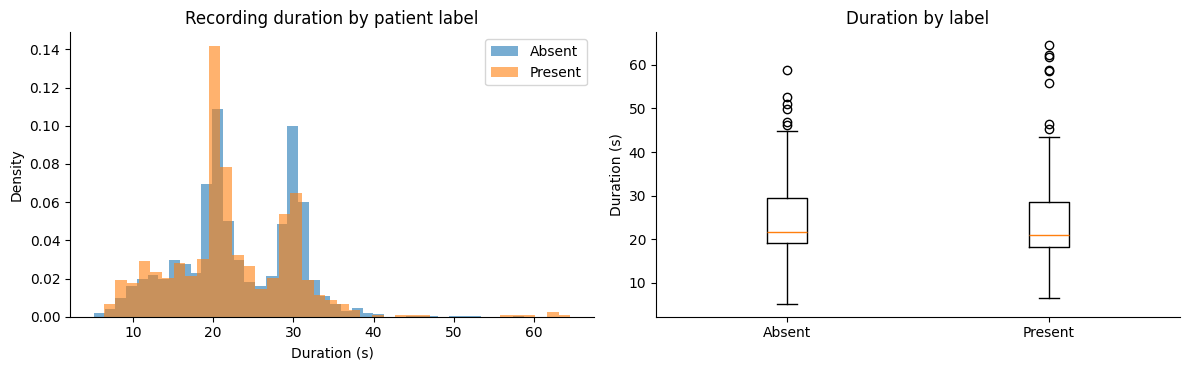

recordings shorter than 1.5 s: 0


In [10]:
def header(path):
    i = sf.info(path)
    return {"path": path, "sr": i.samplerate, "duration_s": i.frames / i.samplerate, "channels": i.channels}
hd = pd.DataFrame(Parallel(n_jobs=-1)(delayed(header)(p) for p in inv["path"]))
inv = inv.merge(hd, on="path").merge(meta[["patient_id", "murmur"]], on="patient_id", how="left")
print("sample rates:", inv["sr"].value_counts().to_dict(), "| channels:", inv["channels"].value_counts().to_dict())
display(inv["duration_s"].describe().round(1).to_frame("duration (s)").T)

fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
for lab, color in [("Absent", "tab:blue"), ("Present", "tab:orange")]:
    axs[0].hist(inv.loc[inv["murmur"] == lab, "duration_s"], bins=40, alpha=0.6, density=True, label=lab, color=color)
axs[0].set_xlabel("Duration (s)"); axs[0].set_ylabel("Density"); axs[0].legend(); axs[0].set_title("Recording duration by patient label")
axs[1].boxplot([inv.loc[inv["murmur"] == l, "duration_s"] for l in ["Absent", "Present"]])
axs[1].set_xticks([1, 2]); axs[1].set_xticklabels(["Absent", "Present"])
axs[1].set_ylabel("Duration (s)"); axs[1].set_title("Duration by label")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/eda4_duration.png", dpi=150); plt.show()
print("recordings shorter than", P.MIN_SEC, "s:", int((inv["duration_s"] < P.MIN_SEC).sum()))

**Interpretation.** _To be written after the run._

<!-- interp:4.4 -->

### 4.5 Signal Level and Quality

Real stethoscope recordings can be noisy, clipped or nearly silent. For every recording the audio is loaded (at the common sample rate) and four quick quality indicators are computed on the **raw** signal, before any filtering:

- **RMS**: overall signal level.
- **Peak**: the largest absolute amplitude.
- **Clipped fraction**: share of samples at the maximum amplitude (distortion).
- **Quiet fraction**: share of 100 ms frames whose level is below 10% of the recording's median frame level (pauses or dropouts).

computed in 47 s


,rms,peak,clipped_frac,quiet_frac
murmur,,,,
Absent,0.0365,1.0,0.0,0.0
Present,0.0466,1.0,0.0,0.0


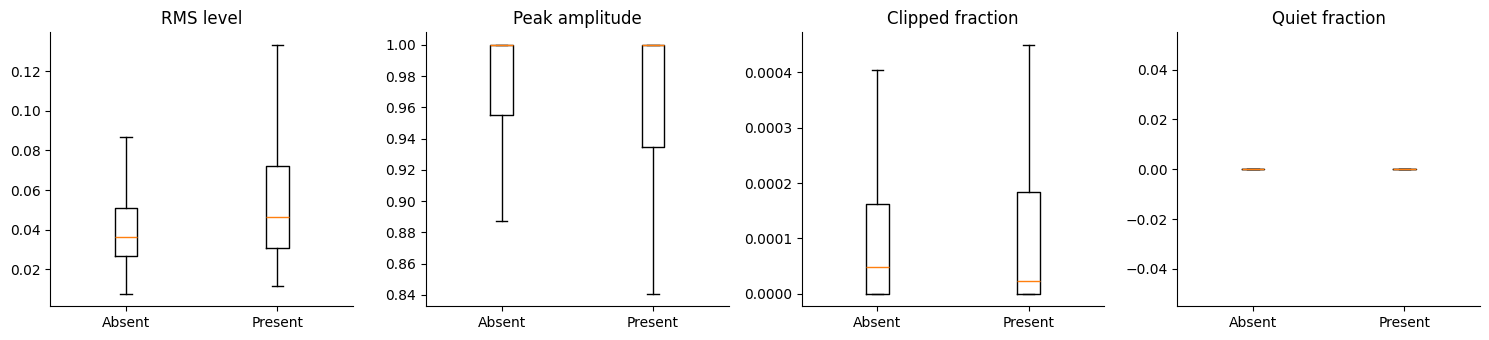

recordings with more than 1% clipped samples: 27 | with more than 30% quiet frames: 0


In [11]:
def audio_stats(path):
    y = P.load_audio(path)
    frame = int(0.1 * P.SR)
    n = len(y) // frame
    fr = np.sqrt((y[: n * frame].reshape(n, frame) ** 2).mean(axis=1)) if n else np.array([0.0])
    return {"path": path, "rms": float(np.sqrt((y ** 2).mean())), "peak": float(np.abs(y).max()),
            "clipped_frac": float((np.abs(y) >= 0.99).mean()), "quiet_frac": float((fr < 0.1 * np.median(fr)).mean())}

t0 = time.time()
qual = pd.DataFrame(Parallel(n_jobs=-1)(delayed(audio_stats)(p) for p in inv["path"]))
inv = inv.merge(qual, on="path")
print("computed in %.0f s" % (time.time() - t0))
sub = inv[inv["murmur"].isin(["Absent", "Present"])]
display(sub.groupby("murmur")[["rms", "peak", "clipped_frac", "quiet_frac"]].median().round(4))

fig, axs = plt.subplots(1, 4, figsize=(15, 3.5))
for ax, col, title in zip(axs, ["rms", "peak", "clipped_frac", "quiet_frac"], ["RMS level", "Peak amplitude", "Clipped fraction", "Quiet fraction"]):
    ax.boxplot([sub.loc[sub["murmur"] == l, col] for l in ["Absent", "Present"]], showfliers=False)
    ax.set_xticks([1, 2]); ax.set_xticklabels(["Absent", "Present"])
    ax.set_title(title)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/eda5_quality.png", dpi=150); plt.show()
print("recordings with more than 1%% clipped samples: %d | with more than 30%% quiet frames: %d"
      % ((inv["clipped_frac"] > 0.01).sum(), (inv["quiet_frac"] > 0.3).sum()))

**Interpretation.** _To be written after the run._

<!-- interp:4.5 -->

### 4.6 What Do Murmur and Normal Recordings Look Like?

One recording from each class, taken at the same auscultation site, shown as the raw waveform and as a spectrogram. The Present example is chosen from a patient whose murmur was annotated at that site.

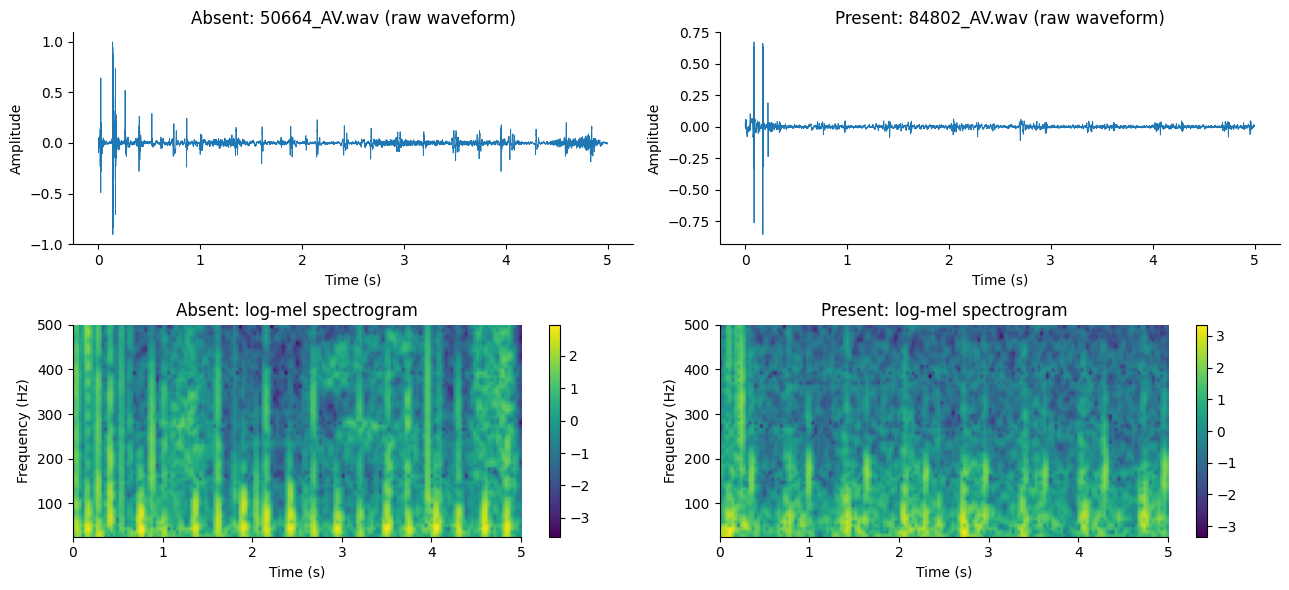

In [12]:
def pick(label, site="AV", seed=SEED):
    c = inv.merge(meta[["patient_id", "murmur_locs"]], on="patient_id", how="left")
    c = c[(c["murmur"] == label) & (c["site"] == site) & (c["duration_s"] >= 8)]
    if label == "Present":
        c = c[c["murmur_locs"].fillna("").apply(lambda s: site in s.split("+"))]
    return c.sample(1, random_state=seed).iloc[0]

examples = {"Absent": pick("Absent"), "Present": pick("Present")}
fig, axs = plt.subplots(2, 2, figsize=(13, 6))
for col, (lab, r) in enumerate(examples.items()):
    y = P.load_audio(r["path"])[: 5 * P.SR]
    t = np.arange(len(y)) / P.SR
    axs[0, col].plot(t, y, lw=0.6); axs[0, col].set_title(f"{lab}: {os.path.basename(r['path'])} (raw waveform)")
    axs[0, col].set_xlabel("Time (s)"); axs[0, col].set_ylabel("Amplitude")
    spec = P.to_logmel(P.bandpass(y)[: int(P.WIN_SEC * P.SR)])
    im = axs[1, col].imshow(spec, origin="lower", aspect="auto", extent=[0, 5, P.LOW_HZ, P.HIGH_HZ], cmap="viridis")
    axs[1, col].set_xlabel("Time (s)"); axs[1, col].set_ylabel("Frequency (Hz)"); axs[1, col].set_title(f"{lab}: log-mel spectrogram")
    plt.colorbar(im, ax=axs[1, col])
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/eda6_examples.png", dpi=150); plt.show()

**Interpretation.** _To be written after the run._

<!-- interp:4.6 -->

### 4.7 Summary of the EDA and the Decisions It Drives

The table below links each finding to a decision in the pipeline. The numbers behind each finding are in the interpretations above.

| Finding | Decision in the pipeline |
|---|---|
| Recordings differ in length | Cut every recording into fixed 5 s windows and average the window predictions per recording |
| Sample rate is not guaranteed to be the same everywhere | Resample everything to 4 kHz |
| Most energy sits at low frequencies, and handling noise sits below the heart sounds | Band-pass filter 25 to 500 Hz, then use a mel spectrogram over the same range |
| Murmurs are a minority class | Class weights during training, and PR-AUC, recall and F1 instead of accuracy |
| Each patient has several similar recordings | Split train, validation and test by patient, with a leakage check |
| Some patients are labelled Unknown, and a Present patient has recordings at sites where the murmur was not heard | A labelling rule that drops these ambiguous recordings (Section 5.1) |
| Recording loudness varies | Standardise each spectrogram window so the model sees shape, not volume |

## 5. Data Preprocessing

### 5.1 Building the Labels

The metadata label belongs to the patient, but the model classifies one recording. Two rules turn patient labels into recording labels:

1. Patients labelled **Unknown** are dropped: their murmur status was not determined.
2. For a patient labelled **Present**, a recording counts as murmur-present only if its auscultation site is listed in that patient's `Murmur locations`. A recording from a murmur patient at a site where the murmur was **not** heard would carry the wrong label, so it is dropped. Recordings from **Absent** patients are all kept as Absent.

`RESTRICT_TO_MURMUR_LOCATIONS` switches rule 2 off, which would keep every recording of a Present patient as Present. The consequence of this rule is stated again in the limitations: the model is validated on recordings where a murmur was annotated at that site, not on every recording from a murmur patient.

In [13]:
RESTRICT_TO_MURMUR_LOCATIONS = True
MAX_WINDOWS_PER_REC = 8

recs = inv[["path", "patient_id", "site", "duration_s"]].merge(meta[["patient_id", "murmur", "murmur_locs"]], on="patient_id", how="inner")

def rec_label(r):
    if r.murmur == "Absent":
        return 0, "kept (Absent)"
    if r.murmur == "Present":
        if not RESTRICT_TO_MURMUR_LOCATIONS:
            return 1, "kept (Present)"
        locs = str(r.murmur_locs).split("+") if isinstance(r.murmur_locs, str) else []
        return (1, "kept (Present at murmur site)") if r.site in locs else (-1, "dropped (Present patient, murmur not heard at this site)")
    return -1, "dropped (Unknown patient)"

lab = recs.apply(rec_label, axis=1, result_type="expand")
recs["label"], recs["reason"] = lab[0], lab[1]
display(recs["reason"].value_counts().to_frame("recordings"))
recs = recs[recs["label"] >= 0].reset_index(drop=True)
print("recordings kept:", len(recs), "| murmur-present share: %.1f%%" % (recs["label"].mean() * 100))

,recordings
reason,
kept (Absent),2391
kept (Present at murmur site),499
dropped (Unknown patient),156
"dropped (Present patient, murmur not heard at this site)",117


recordings kept: 2890 | murmur-present share: 17.3%


### 5.2 The Signal Processing Pipeline

Each recording goes through five steps, implemented in `preprocessing.py`:

1. **Load and resample** to 4 kHz and a single channel, so every recording has the same time resolution.
2. **Band-pass filter, 25 to 500 Hz** (4th-order Butterworth, applied forwards and backwards so the timing of the heart sounds is not shifted). Below 25 Hz there is mostly handling and stethoscope-movement noise, and above 500 Hz there is little heart sound or murmur energy.
3. **Cut into 5 s windows**, without overlap. The last partial window is zero-padded if it contains at least 1.5 s of signal, otherwise it is dropped. At most 8 windows are used per recording.
4. **Log-mel spectrogram** with 64 mel bands between 25 and 500 Hz (512-sample FFT, 128-sample hop), giving a 64 by 157 image per window. The log scale compresses the large dynamic range, as in human hearing.
5. **Standardise each window** to zero mean and unit variance, so the model compares spectral shape, not recording volume.

The figure follows one recording through these steps.

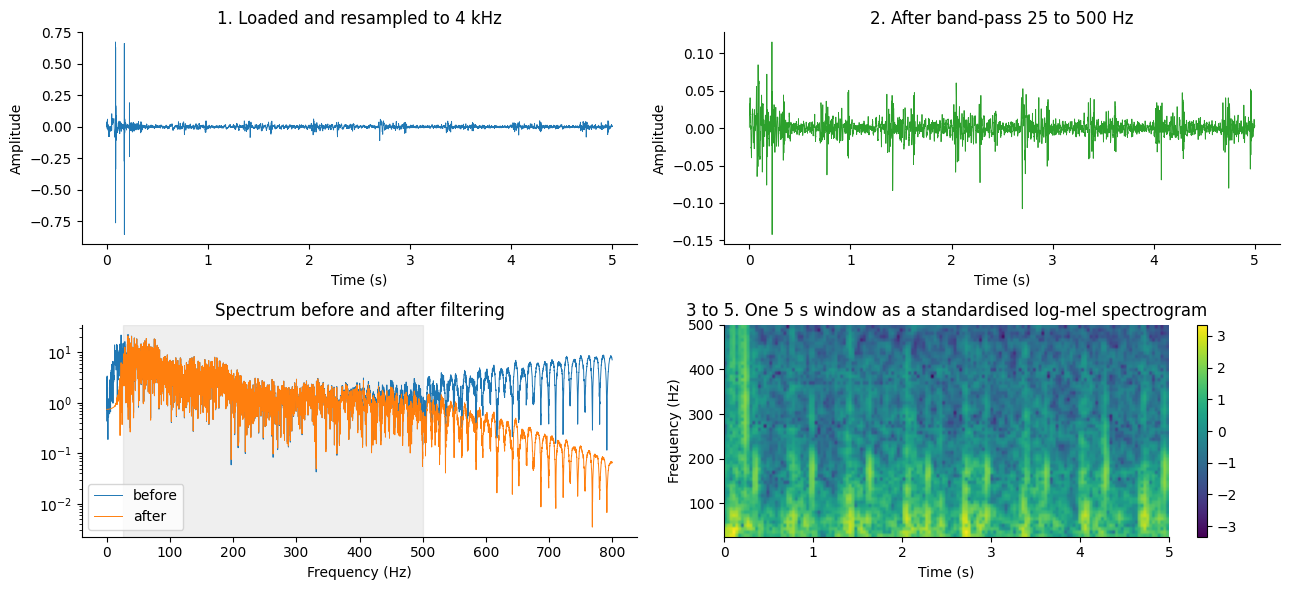

one recording of 19.8 s becomes 4 window(s) of shape (64, 157)


In [14]:
r = examples["Present"]
y_raw = P.load_audio(r["path"])
y_bp = P.bandpass(y_raw)
win = P.split_windows(y_bp, 1)[0]
spec = P.to_logmel(win)
seg = slice(0, 5 * P.SR)
t = np.arange(5 * P.SR) / P.SR
fig, axs = plt.subplots(2, 2, figsize=(13, 6))
axs[0, 0].plot(t, y_raw[seg], lw=0.6); axs[0, 0].set_title("1. Loaded and resampled to 4 kHz")
axs[0, 1].plot(t, y_bp[seg], lw=0.6, color="tab:green"); axs[0, 1].set_title("2. After band-pass 25 to 500 Hz")
f_raw = np.abs(np.fft.rfft(y_raw[seg])); f_bp = np.abs(np.fft.rfft(y_bp[seg])); fr = np.fft.rfftfreq(5 * P.SR, 1 / P.SR)
axs[1, 0].semilogy(fr[fr < 800], f_raw[fr < 800], lw=0.7, label="before"); axs[1, 0].semilogy(fr[fr < 800], f_bp[fr < 800], lw=0.7, label="after")
axs[1, 0].axvspan(P.LOW_HZ, P.HIGH_HZ, color="gray", alpha=0.12); axs[1, 0].set_title("Spectrum before and after filtering"); axs[1, 0].set_xlabel("Frequency (Hz)"); axs[1, 0].legend()
im = axs[1, 1].imshow(spec, origin="lower", aspect="auto", extent=[0, 5, P.LOW_HZ, P.HIGH_HZ]); plt.colorbar(im, ax=axs[1, 1])
axs[1, 1].set_title("3 to 5. One 5 s window as a standardised log-mel spectrogram"); axs[1, 1].set_xlabel("Time (s)"); axs[1, 1].set_ylabel("Frequency (Hz)")
for a in axs[0]: a.set_xlabel("Time (s)"); a.set_ylabel("Amplitude")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/prep1_pipeline.png", dpi=150); plt.show()
print("one recording of %.1f s becomes %d window(s) of shape %s" % (len(y_raw) / P.SR, len(P.split_windows(y_bp)), spec.shape))

**Interpretation.** _To be written after the run._

<!-- interp:5.2 -->

### 5.3 Patient-Wise Train, Validation and Test Split

Patients are split 70% / 15% / 15%, stratified on the patient's murmur label so each split has a similar murmur rate. All recordings of a patient go to the same split. The code asserts that no patient appears in more than one split.

- **Training**: fits the model weights.
- **Validation**: used to stop training early, to choose between the experiments and to choose the decision threshold.
- **Test**: used once, at the end, for the reported performance.

In [15]:
pat = recs.groupby("patient_id")["murmur"].first().reset_index()
tr_p, tmp_p = train_test_split(pat, test_size=0.30, stratify=pat["murmur"], random_state=SEED)
va_p, te_p = train_test_split(tmp_p, test_size=0.50, stratify=tmp_p["murmur"], random_state=SEED)
split_of = {**{i: "train" for i in tr_p.patient_id}, **{i: "val" for i in va_p.patient_id}, **{i: "test" for i in te_p.patient_id}}
recs["split"] = recs["patient_id"].map(split_of)
assert recs.groupby("patient_id")["split"].nunique().max() == 1, "a patient appears in more than one split"
summary = recs.groupby("split").agg(patients=("patient_id", "nunique"), recordings=("path", "count"),
                                    murmur_recordings=("label", "sum"), murmur_rate=("label", "mean")).loc[["train", "val", "test"]]
display(summary.round(3))
print("leakage check passed: no patient is shared between splits")

,patients,recordings,murmur_recordings,murmur_rate
split,,,,
train,611,2010,348,0.173
val,131,421,71,0.169
test,132,459,80,0.174


leakage check passed: no patient is shared between splits


**Interpretation.** _To be written after the run._

<!-- interp:5.3 -->

### 5.4 Feature Extraction

Every kept recording is converted to spectrogram windows once, in parallel, and saved to disk. All later cells (and the deployed retraining code) work from these arrays, and arrays are stored as 16-bit floats to save memory.

In [16]:
def extract(i, path):
    return i, P.wav_to_features(path, max_windows=MAX_WINDOWS_PER_REC)

t0 = time.time()
results = Parallel(n_jobs=-1)(delayed(extract)(i, r.path) for i, r in recs.iterrows())
for split in ["train", "val", "test"]:
    X, y, rec_id, pat_id = [], [], [], []
    for i, feats in results:
        r = recs.loc[i]
        if r.split != split or len(feats) == 0:
            continue
        n = len(feats)
        X.append(feats.astype(np.float16)); y += [r.label] * n; rec_id += [i] * n; pat_id += [r.patient_id] * n
    np.savez_compressed(f"{OUT_DIR}/{split}.npz", X=np.concatenate(X), y=np.array(y), rec_id=np.array(rec_id), patient_id=np.array(pat_id))
print("feature extraction took %.0f s" % (time.time() - t0))

D = {s: np.load(f"{OUT_DIR}/{s}.npz") for s in ["train", "val", "test"]}
Xtr, ytr = D["train"]["X"], D["train"]["y"].astype("float32")
Xva, yva = D["val"]["X"], D["val"]["y"].astype("float32")
Xte, yte = D["test"]["X"], D["test"]["y"].astype("float32")
for name, X, y in [("train", Xtr, ytr), ("val", Xva, yva), ("test", Xte, yte)]:
    print(f"{name:5s} windows {X.shape} | murmur windows {int(y.sum())} ({y.mean():.1%})")

feature extraction took 33 s
train windows (9562, 64, 157, 1) | murmur windows 1633 (17.1%)
val   windows (1948, 64, 157, 1) | murmur windows 323 (16.6%)
test  windows (2118, 64, 157, 1) | murmur windows 352 (16.6%)


### 5.5 Class Weights, Input Pipeline and Augmentation

- **Class weights** (balanced): the loss gives murmur windows a larger weight, so the model is not rewarded for always predicting Absent.
- **tf.data pipeline**: shuffles, batches (64) and converts the stored 16-bit arrays to 32-bit floats.
- **SpecAugment-style masking** (used only in Experiment 3): during training, a random band of up to 8 mel bands and a random stretch of up to 20 time frames are set to zero. It makes the model robust to missing information and acts as a regulariser.

In [17]:
cw = compute_class_weight("balanced", classes=np.array([0., 1.]), y=ytr)
class_weight = {0: float(cw[0]), 1: float(cw[1])}
print("class weights:", {k: round(v, 3) for k, v in class_weight.items()})

N_MELS_, N_T_ = Xtr.shape[1], Xtr.shape[2]

def spec_augment(x, y, max_freq=8, max_time=20):
    x = tf.cast(x, tf.float32)
    f = tf.random.uniform([], 0, max_freq + 1, dtype=tf.int32)
    f0 = tf.random.uniform([], 0, N_MELS_ - f + 1, dtype=tf.int32)
    t = tf.random.uniform([], 0, max_time + 1, dtype=tf.int32)
    t0 = tf.random.uniform([], 0, N_T_ - t + 1, dtype=tf.int32)
    rows, cols = tf.range(N_MELS_), tf.range(N_T_)
    keep_r = tf.cast(tf.logical_or(rows < f0, rows >= f0 + f), tf.float32)[:, None, None]
    keep_c = tf.cast(tf.logical_or(cols < t0, cols >= t0 + t), tf.float32)[None, :, None]
    return x * keep_r * keep_c, y

def make_ds(X, y, shuffle=False, bs=64, augment=False):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if shuffle:
        ds = ds.shuffle(4096, seed=SEED)
    if augment:
        ds = ds.map(spec_augment, num_parallel_calls=tf.data.AUTOTUNE).batch(bs)
    else:
        ds = ds.batch(bs).map(lambda a, b: (tf.cast(a, tf.float32), b))
    return ds.prefetch(tf.data.AUTOTUNE)

xb, _ = next(iter(make_ds(Xtr[:8], ytr[:8], augment=True)))
print("augmented batch:", xb.shape, "| share of zeros in the first example: %.1f%%" % (float((xb[0] == 0).numpy().mean()) * 100))

class weights: {0: 0.603, 1: 2.928}
augmented batch: (8, 64, 157, 1) | share of zeros in the first example: 13.8%


## 6. Visualizations of the Processed Data

The EDA in Section 4 looked at the raw recordings. These visualizations look at the data the model actually sees: the labelled recordings, the splits and the spectrograms.

### 6.1 Visualization 1: Class Balance per Split

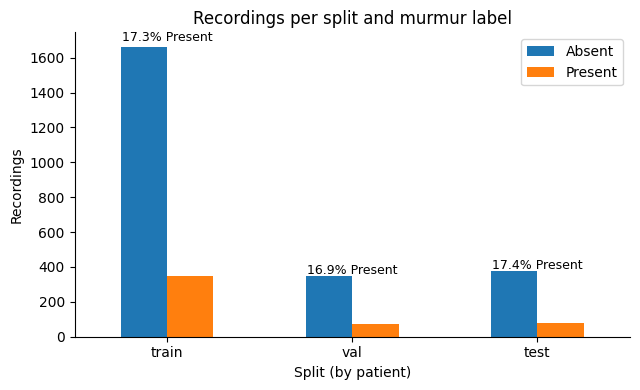

,Absent,Present
split,,
train,1662,348
val,350,71
test,379,80


accuracy of a model that always answers Absent: train 82.7% | val 83.1% | test 82.6%


In [18]:
ct = recs.groupby(["split", "label"]).size().unstack(fill_value=0).loc[["train", "val", "test"]]
ct.columns = ["Absent", "Present"]
fig, ax = plt.subplots(figsize=(6.5, 4))
ct.plot.bar(ax=ax, rot=0)
for i, s in enumerate(ct.index):
    ax.text(i, ct.loc[s].max() * 1.02, f"{ct.loc[s, 'Present'] / ct.loc[s].sum():.1%} Present", ha="center", fontsize=9)
ax.set_ylabel("Recordings"); ax.set_xlabel("Split (by patient)"); ax.set_title("Recordings per split and murmur label")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig1_class_balance.png", dpi=150); plt.show()
display(ct)
print("accuracy of a model that always answers Absent: train %.1f%% | val %.1f%% | test %.1f%%" %
      tuple(100 * ct.loc[s, "Absent"] / ct.loc[s].sum() for s in ["train", "val", "test"]))

**Interpretation.** _To be written after the run._

<!-- interp:6.1 -->

### 6.2 Visualization 2: Murmur Rate by Auscultation Site

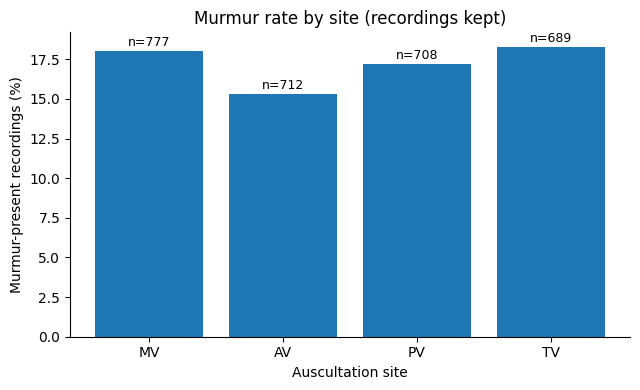

site,MV,AV,PV,TV
rate,18.0,15.3,17.2,18.3
n,777.0,712.0,708.0,689.0


In [19]:
site = recs.groupby("site")["label"].agg(rate="mean", n="count")
site = site[site["n"] >= 20].sort_values("n", ascending=False)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.bar(site.index, site["rate"] * 100)
for i, s in enumerate(site.index):
    ax.text(i, site.loc[s, "rate"] * 100 + 0.3, f"n={int(site.loc[s, 'n'])}", ha="center", fontsize=9)
ax.set_ylabel("Murmur-present recordings (%)"); ax.set_xlabel("Auscultation site"); ax.set_title("Murmur rate by site (recordings kept)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig2_murmur_by_site.png", dpi=150); plt.show()
display((site.assign(rate=(site["rate"] * 100).round(1))).T)

**Interpretation.** _To be written after the run._

<!-- interp:6.2 -->

### 6.3 Visualization 3: Mean Spectrograms by Class

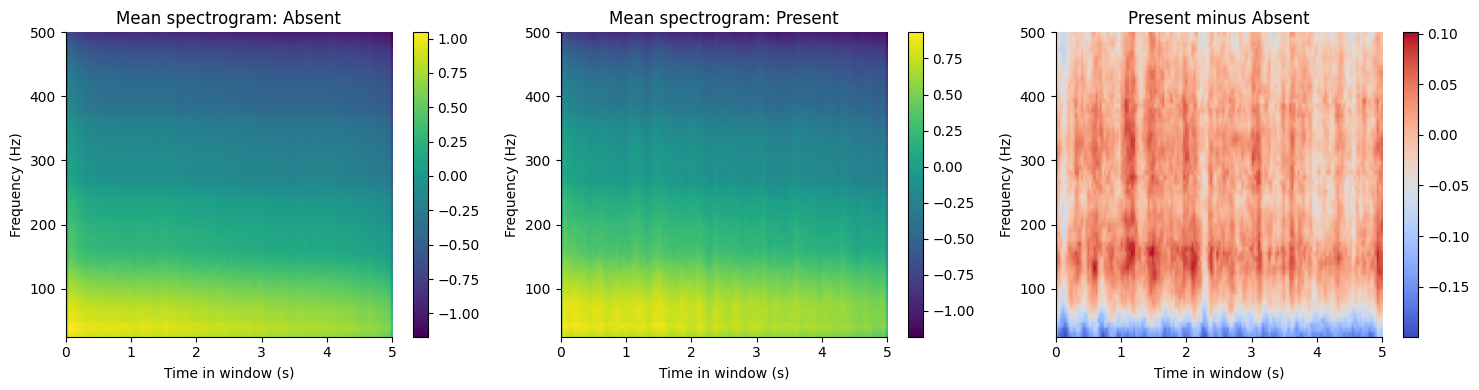

training windows averaged: Absent 7929, Present 1633
largest positive difference: 0.041 at 153 Hz | largest negative: -0.145 at 25 Hz


In [20]:
hz = np.linspace(P.LOW_HZ, P.HIGH_HZ, P.N_MELS)     # mel centres are linear in this band
Xf = Xtr.astype("float32")[..., 0]
m0, m1 = Xf[ytr == 0].mean(0), Xf[ytr == 1].mean(0)
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for ax, img, title, cmap in [(axs[0], m0, "Mean spectrogram: Absent", "viridis"), (axs[1], m1, "Mean spectrogram: Present", "viridis"),
                             (axs[2], m1 - m0, "Present minus Absent", "coolwarm")]:
    im = ax.imshow(img, origin="lower", aspect="auto", extent=[0, P.WIN_SEC, P.LOW_HZ, P.HIGH_HZ], cmap=cmap)
    ax.set_xlabel("Time in window (s)"); ax.set_ylabel("Frequency (Hz)"); ax.set_title(title); plt.colorbar(im, ax=ax)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig3_mean_spectrograms.png", dpi=150); plt.show()
print("training windows averaged: Absent %d, Present %d" % ((ytr == 0).sum(), (ytr == 1).sum()))
print("largest positive difference: %.3f at %.0f Hz | largest negative: %.3f at %.0f Hz" %
      ((m1 - m0).mean(1).max(), hz[(m1 - m0).mean(1).argmax()], (m1 - m0).mean(1).min(), hz[(m1 - m0).mean(1).argmin()]))

**Interpretation.** _To be written after the run._

<!-- interp:6.3 -->

### 6.4 Visualization 4: Energy by Frequency Band

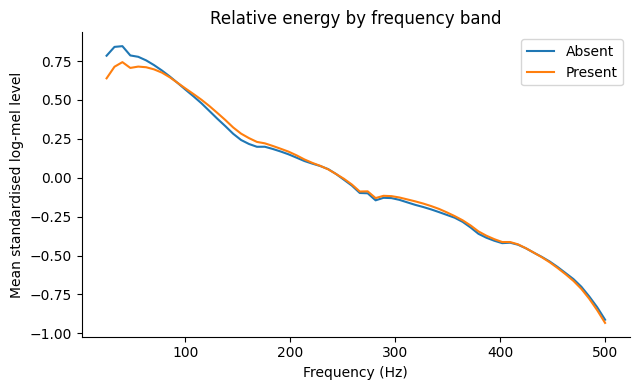

,band (Hz),Absent,Present,difference
0,25-80,0.776,0.700,-0.075
1,80-200,0.351,0.374,0.024
2,200-500,-0.280,-0.273,0.006


In [21]:
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(hz, m0.mean(1), label="Absent"); ax.plot(hz, m1.mean(1), label="Present")
ax.set_xlabel("Frequency (Hz)"); ax.set_ylabel("Mean standardised log-mel level"); ax.legend(); ax.set_title("Relative energy by frequency band")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig4_band_profile.png", dpi=150); plt.show()
bands = [(25, 80), (80, 200), (200, 500)]
rows = [{"band (Hz)": f"{lo}-{hi}", "Absent": m0.mean(1)[(hz >= lo) & (hz < hi)].mean(), "Present": m1.mean(1)[(hz >= lo) & (hz < hi)].mean()} for lo, hi in bands]
display(pd.DataFrame(rows).assign(difference=lambda d: d["Present"] - d["Absent"]).round(3))

**Interpretation.** _To be written after the run._

<!-- interp:6.4 -->

### 6.5 Visualization 5: How Separable Are the Windows? (PCA)

A two-component PCA of 3,000 randomly chosen training windows (flattened spectrograms) gives a rough view of whether the classes separate without any learning. If they overlap heavily in this projection, a model has to find structure that this simple projection cannot.

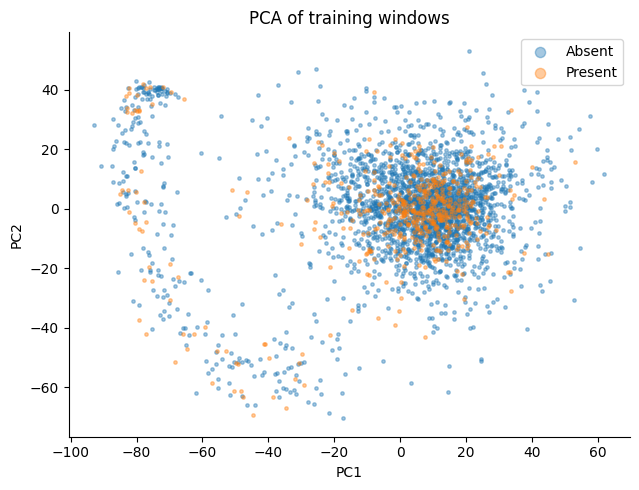

variance explained by the two components: 13.4%


In [22]:
rng = np.random.default_rng(SEED)
idx = rng.choice(len(Xtr), size=min(3000, len(Xtr)), replace=False)
Z = PCA(n_components=2, random_state=SEED).fit(Xtr[idx].reshape(len(idx), -1).astype("float32"))
emb = Z.transform(Xtr[idx].reshape(len(idx), -1).astype("float32"))
fig, ax = plt.subplots(figsize=(6.5, 5))
for lbl, name, color in [(0, "Absent", "tab:blue"), (1, "Present", "tab:orange")]:
    m = ytr[idx] == lbl
    ax.scatter(emb[m, 0], emb[m, 1], s=6, alpha=0.4, label=name, color=color)
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.legend(markerscale=3); ax.set_title("PCA of training windows")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig7_pca.png", dpi=150); plt.show()
print("variance explained by the two components: %.1f%%" % (Z.explained_variance_ratio_.sum() * 100))

**Interpretation.** _To be written after the run._

<!-- interp:6.5 -->

## 7. Model Creation

Three CNN experiments are trained on the log-mel spectrograms, each adding techniques to the previous one, so the effect of each addition can be measured against a common baseline.

| | Experiment 1: baseline | Experiment 2: regularised | Experiment 3: deeper with augmentation |
|---|---|---|---|
| Convolution blocks | 2 (16, 32 filters) | 3 (16, 32, 64) | 4 (16, 32, 64, 128) |
| Batch normalisation | no | yes | yes |
| Dropout | no | 0.3 | 0.3 |
| L2 weight penalty | no | no | 1e-4 |
| Class weights | no | yes | yes |
| SpecAugment masking | no | no | yes |
| Early stopping and learning-rate schedule | no (fixed 15 epochs) | yes | yes |

**Optimization techniques used across the experiments:** Adam optimizer, learning-rate reduction on plateau, early stopping on validation PR-AUC with the best weights restored, dropout, L2 regularisation, batch normalisation, class weighting, data augmentation, and a comparison of three architectures with selection on validation data.

All networks use global average pooling and one sigmoid output, which keeps them small enough to retrain on a CPU inside the deployed application. Early stopping watches **validation PR-AUC**, not validation loss, because loss is dominated by the many Absent windows.

In [23]:
def build_baseline_cnn(input_shape):
    inp = keras.Input(shape=input_shape)
    x = layers.Conv2D(16, 3, padding="same", activation="relu")(inp); x = layers.MaxPool2D(2)(x)
    x = layers.Conv2D(32, 3, padding="same", activation="relu")(x); x = layers.MaxPool2D(2)(x)
    x = layers.GlobalAveragePooling2D()(x)
    return keras.Model(inp, layers.Dense(1, activation="sigmoid")(x))

def build_cnn(input_shape, filters=(16, 32, 64), dropout=0.3, l2=0.0):
    reg = regularizers.l2(l2) if l2 else None
    inp = keras.Input(shape=input_shape)
    x = inp
    for f in filters:
        x = layers.Conv2D(f, 3, padding="same", use_bias=False, kernel_regularizer=reg)(x)
        x = layers.BatchNormalization()(x)
        x = layers.ReLU()(x)
        x = layers.MaxPool2D(2)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout)(x)
    return keras.Model(inp, layers.Dense(1, activation="sigmoid", kernel_regularizer=reg)(x))

def compile_model(m, lr=1e-3):
    m.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy",
              metrics=[keras.metrics.AUC(name="auc"), keras.metrics.AUC(curve="PR", name="pr_auc")])
    return m

def predict(m, X, bs=64):
    return np.concatenate([m(X[i:i + bs].astype("float32"), training=False).numpy().ravel() for i in range(0, len(X), bs)])

def per_recording(p, y, rec_id):
    df = pd.DataFrame({"p": p, "y": y, "rec": rec_id}).groupby("rec").agg(p=("p", "mean"), y=("y", "first"))
    return df["p"].values, df["y"].values.astype(int)

def callbacks_with_early_stopping():
    return [keras.callbacks.EarlyStopping(monitor="val_pr_auc", mode="max", patience=6, restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3)]

EXPERIMENTS = {}
def train_experiment(name, model, epochs, callbacks=(), use_class_weight=False, augment=False):
    compile_model(model)
    t0 = time.time()
    h = model.fit(make_ds(Xtr, ytr, shuffle=True, augment=augment), validation_data=make_ds(Xva, yva), epochs=epochs,
                  class_weight=class_weight if use_class_weight else None, callbacks=list(callbacks), verbose=2)
    EXPERIMENTS[name] = {"model": model, "history": h.history, "minutes": (time.time() - t0) / 60,
                         "params": model.count_params(), "epochs_run": len(h.history["loss"])}
    print(f"{name}: {model.count_params():,} parameters, {len(h.history['loss'])} epochs, {(time.time() - t0) / 60:.1f} min")

### 7.1 Experiment 1: Simple CNN Baseline

Two convolution and pooling blocks followed by one output unit, with no regularisation, no class weights and no early stopping. It sets a reference point: how well a minimal network does on imbalanced data, and how much the later techniques add.

In [24]:
tf.keras.utils.set_random_seed(SEED)
m1 = build_baseline_cnn(Xtr.shape[1:])
train_experiment("1_baseline", m1, epochs=15)

Epoch 1/15


E0000 00:00:1795366728.217371     191 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


150/150 - 15s - 103ms/step - auc: 0.5476 - loss: 0.4616 - pr_auc: 0.1861 - val_auc: 0.4904 - val_loss: 0.4566 - val_pr_auc: 0.1697
Epoch 2/15
150/150 - 2s - 11ms/step - auc: 0.5879 - loss: 0.4518 - pr_auc: 0.2069 - val_auc: 0.5044 - val_loss: 0.4563 - val_pr_auc: 0.1765
Epoch 3/15
150/150 - 2s - 11ms/step - auc: 0.6351 - loss: 0.4441 - pr_auc: 0.2434 - val_auc: 0.5363 - val_loss: 0.4508 - val_pr_auc: 0.1924
Epoch 4/15
150/150 - 2s - 11ms/step - auc: 0.7117 - loss: 0.4212 - pr_auc: 0.4313 - val_auc: 0.5916 - val_loss: 0.4402 - val_pr_auc: 0.2937
Epoch 5/15
150/150 - 2s - 11ms/step - auc: 0.7784 - loss: 0.3742 - pr_auc: 0.5877 - val_auc: 0.6049 - val_loss: 0.4672 - val_pr_auc: 0.3071
Epoch 6/15
150/150 - 2s - 11ms/step - auc: 0.7886 - loss: 0.3510 - pr_auc: 0.6130 - val_auc: 0.6282 - val_loss: 0.4302 - val_pr_auc: 0.3438
Epoch 7/15
150/150 - 2s - 11ms/step - auc: 0.7962 - loss: 0.3406 - pr_auc: 0.6225 - val_auc: 0.6417 - val_loss: 0.4284 - val_pr_auc: 0.3534
Epoch 8/15
150/150 - 2s - 11m

### 7.2 Experiment 2: Regularised CNN

Adds a third block, batch normalisation after each convolution, dropout before the output, class weights, early stopping on validation PR-AUC and a learning-rate schedule.

In [25]:
tf.keras.utils.set_random_seed(SEED)
m2 = build_cnn(Xtr.shape[1:], filters=(16, 32, 64), dropout=0.3)
train_experiment("2_regularised", m2, epochs=40, callbacks=callbacks_with_early_stopping(), use_class_weight=True)

Epoch 1/40
150/150 - 16s - 109ms/step - auc: 0.7751 - loss: 0.5523 - pr_auc: 0.5784 - val_auc: 0.6875 - val_loss: 1.0272 - val_pr_auc: 0.4428 - learning_rate: 0.0010
Epoch 2/40
150/150 - 2s - 15ms/step - auc: 0.8218 - loss: 0.4983 - pr_auc: 0.6570 - val_auc: 0.6989 - val_loss: 1.5473 - val_pr_auc: 0.4704 - learning_rate: 0.0010
Epoch 3/40
150/150 - 2s - 15ms/step - auc: 0.8453 - loss: 0.4697 - pr_auc: 0.6926 - val_auc: 0.7652 - val_loss: 0.8454 - val_pr_auc: 0.5298 - learning_rate: 0.0010
Epoch 4/40
150/150 - 2s - 15ms/step - auc: 0.8673 - loss: 0.4432 - pr_auc: 0.7126 - val_auc: 0.7720 - val_loss: 0.5582 - val_pr_auc: 0.5477 - learning_rate: 0.0010
Epoch 5/40
150/150 - 2s - 15ms/step - auc: 0.8710 - loss: 0.4379 - pr_auc: 0.7176 - val_auc: 0.7625 - val_loss: 0.3789 - val_pr_auc: 0.5471 - learning_rate: 0.0010
Epoch 6/40
150/150 - 2s - 15ms/step - auc: 0.8794 - loss: 0.4244 - pr_auc: 0.7326 - val_auc: 0.7695 - val_loss: 0.5584 - val_pr_auc: 0.5668 - learning_rate: 0.0010
Epoch 7/40
150

### 7.3 Experiment 3: Deeper CNN with L2 and SpecAugment

Adds a fourth block with 128 filters, an L2 weight penalty and SpecAugment masking on the training windows. It is the highest-capacity and most heavily regularised model.

In [26]:
tf.keras.utils.set_random_seed(SEED)
m3 = build_cnn(Xtr.shape[1:], filters=(16, 32, 64, 128), dropout=0.3, l2=1e-4)
train_experiment("3_deep_l2_specaugment", m3, epochs=40, callbacks=callbacks_with_early_stopping(), use_class_weight=True, augment=True)

Epoch 1/40
150/150 - 21s - 138ms/step - auc: 0.8111 - loss: 0.5345 - pr_auc: 0.6430 - val_auc: 0.7904 - val_loss: 0.5603 - val_pr_auc: 0.5654 - learning_rate: 0.0010
Epoch 2/40
150/150 - 3s - 18ms/step - auc: 0.8663 - loss: 0.4605 - pr_auc: 0.7236 - val_auc: 0.7863 - val_loss: 1.3025 - val_pr_auc: 0.5900 - learning_rate: 0.0010
Epoch 3/40
150/150 - 3s - 17ms/step - auc: 0.8923 - loss: 0.4155 - pr_auc: 0.7713 - val_auc: 0.8281 - val_loss: 0.5681 - val_pr_auc: 0.6452 - learning_rate: 0.0010
Epoch 4/40
150/150 - 3s - 17ms/step - auc: 0.9035 - loss: 0.3978 - pr_auc: 0.7864 - val_auc: 0.8243 - val_loss: 0.8685 - val_pr_auc: 0.6518 - learning_rate: 0.0010
Epoch 5/40
150/150 - 3s - 17ms/step - auc: 0.9265 - loss: 0.3551 - pr_auc: 0.8193 - val_auc: 0.8318 - val_loss: 0.4216 - val_pr_auc: 0.6562 - learning_rate: 5.0000e-04
Epoch 6/40
150/150 - 3s - 17ms/step - auc: 0.9291 - loss: 0.3479 - pr_auc: 0.8291 - val_auc: 0.8229 - val_loss: 0.3984 - val_pr_auc: 0.6424 - learning_rate: 5.0000e-04
Epoch 

All three experiments are trained and stored in `EXPERIMENTS` with their histories, parameter counts and training times. Section 8 compares them on the **validation** set.

## 8. Model Evaluation

The three experiments are compared on validation data only. The test set is not used to choose between them, so that the final test result is an honest estimate and not the best of several looks.

### 8.1 Training History

Training and validation loss, and training and validation PR-AUC, for each experiment. A dashed line marks the epoch kept by early stopping, where one was used.

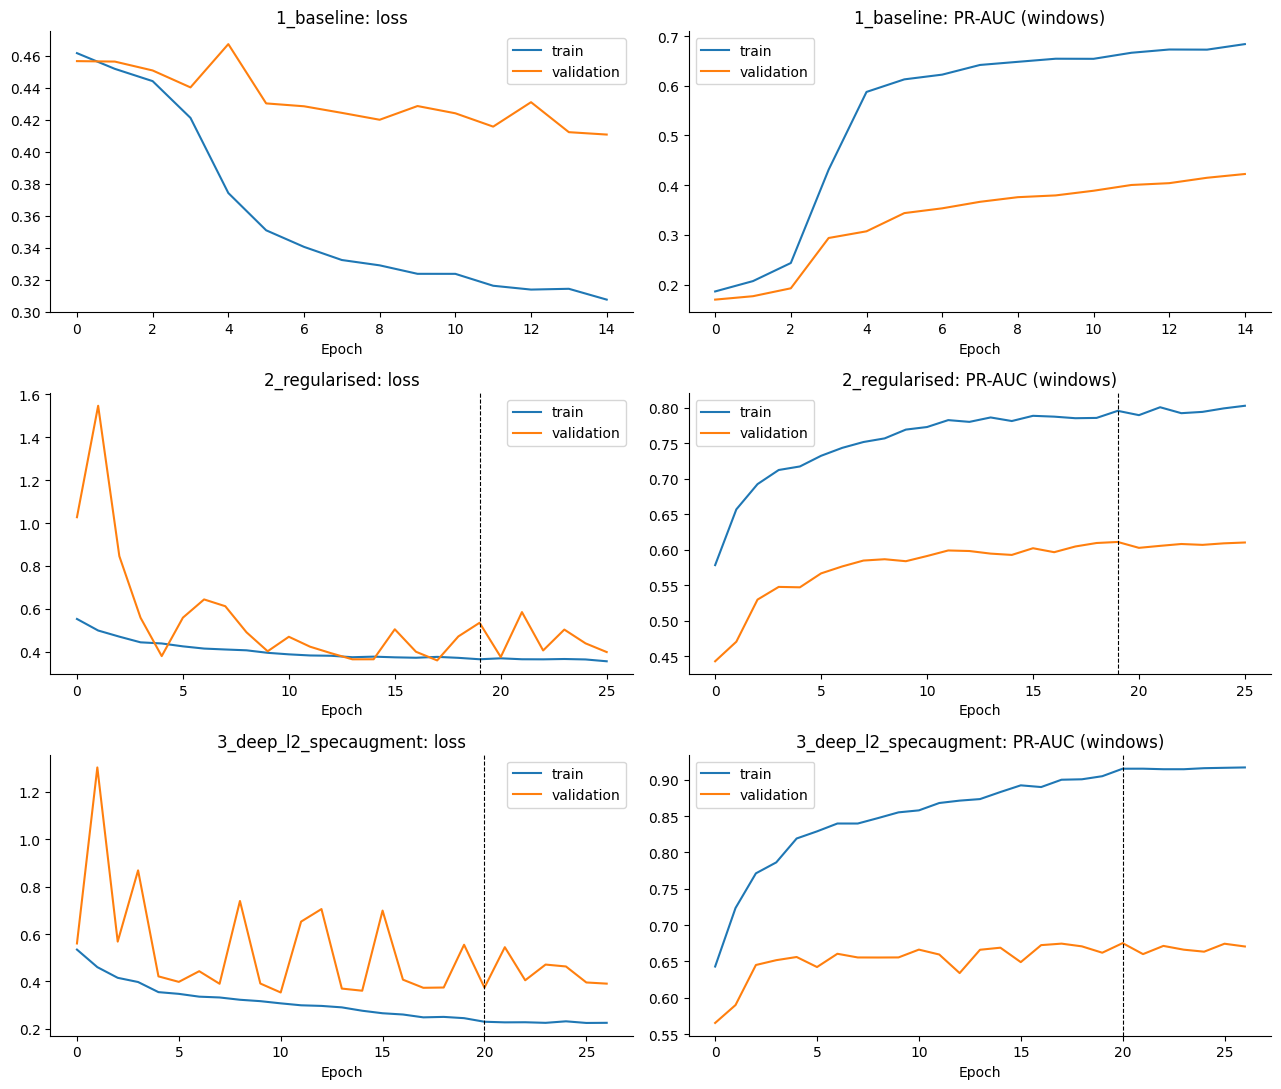

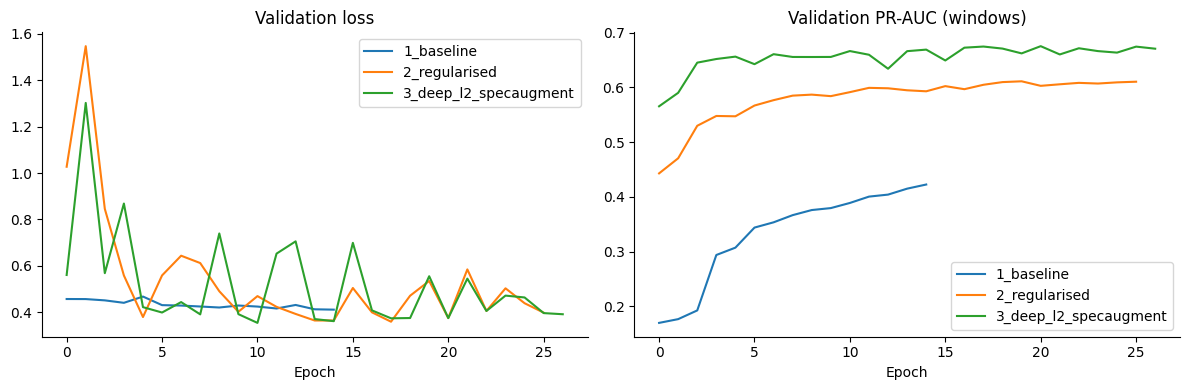

In [27]:
fig, axs = plt.subplots(3, 2, figsize=(13, 11))
for row, (name, e) in enumerate(EXPERIMENTS.items()):
    H = e["history"]
    axs[row, 0].plot(H["loss"], label="train"); axs[row, 0].plot(H["val_loss"], label="validation")
    axs[row, 0].set_title(f"{name}: loss"); axs[row, 0].set_xlabel("Epoch"); axs[row, 0].legend()
    axs[row, 1].plot(H["pr_auc"], label="train"); axs[row, 1].plot(H["val_pr_auc"], label="validation")
    axs[row, 1].set_title(f"{name}: PR-AUC (windows)"); axs[row, 1].set_xlabel("Epoch"); axs[row, 1].legend()
    if name != "1_baseline":
        for a in axs[row]: a.axvline(int(np.argmax(H["val_pr_auc"])), color="k", ls="--", lw=0.8)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/eval1_training_histories.png", dpi=150); plt.show()

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for name, e in EXPERIMENTS.items():
    axs[0].plot(e["history"]["val_loss"], label=name); axs[1].plot(e["history"]["val_pr_auc"], label=name)
axs[0].set_title("Validation loss"); axs[1].set_title("Validation PR-AUC (windows)")
for a in axs: a.set_xlabel("Epoch"); a.legend()
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/eval2_validation_comparison.png", dpi=150); plt.show()

**Interpretation.** _To be written after the run._

<!-- interp:8.1 -->

### 8.2 Validation Comparison Table

Every experiment is scored on the validation set with the same metrics. Window-level metrics use a fixed 0.5 threshold so the experiments are compared on equal terms. Recording-level scores average the window probabilities per recording, which is how the deployed application predicts, and the **recording-level validation PR-AUC** is the criterion for choosing the final model. PR-AUC is preferred to accuracy because it does not depend on a threshold and it is sensitive to the minority class.

In [28]:
def window_metrics(y, p, thr=0.5):
    pred = (p >= thr).astype(int)
    return {"loss": log_loss(y, p, labels=[0, 1]), "accuracy": accuracy_score(y, pred),
            "precision": precision_score(y, pred, zero_division=0), "recall": recall_score(y, pred, zero_division=0),
            "f1": f1_score(y, pred, zero_division=0), "roc_auc": roc_auc_score(y, p), "pr_auc": average_precision_score(y, p)}

val_pred, rows = {}, []
for name, e in EXPERIMENTS.items():
    p = predict(e["model"], Xva)
    val_pred[name] = p
    wm = window_metrics(yva, p)
    rp, ry = per_recording(p, yva, D["val"]["rec_id"])
    H = e["history"]
    best = int(np.argmax(H["val_pr_auc"])) if name != "1_baseline" else len(H["loss"]) - 1
    rows.append({"experiment": name, "parameters": e["params"], "epochs_run": e["epochs_run"], "kept_epoch": best + 1,
                 "minutes": round(e["minutes"], 1), "train_pr_auc": round(H["pr_auc"][best], 3),
                 **{f"val_{k}": round(v, 3) for k, v in wm.items()},
                 "val_rec_roc_auc": round(roc_auc_score(ry, rp), 3), "val_rec_pr_auc": round(average_precision_score(ry, rp), 3)})
results = pd.DataFrame(rows)
results.to_csv(f"{RES_DIR}/experiments.csv", index=False)
display(results.set_index("experiment").T)

experiment,1_baseline,2_regularised,3_deep_l2_specaugment
parameters,4833.000,23697.000,98001.000
epochs_run,15.000,26.000,27.000
kept_epoch,15.000,20.000,21.000
minutes,0.700,1.200,1.500
train_pr_auc,0.684,0.796,0.915
val_loss,0.411,0.534,0.358
val_accuracy,0.849,0.719,0.880
val_precision,0.746,0.336,0.670
val_recall,0.136,0.712,0.548
val_f1,0.230,0.456,0.603


### 8.3 Selecting the Final Model

In [29]:
best_name = results.sort_values("val_rec_pr_auc").iloc[-1]["experiment"]
model, hist = EXPERIMENTS[best_name]["model"], EXPERIMENTS[best_name]["history"]
print("Selected model:", best_name, "| criterion: validation recording-level PR-AUC =", results.set_index("experiment").loc[best_name, "val_rec_pr_auc"])

Selected model: 3_deep_l2_specaugment | criterion: validation recording-level PR-AUC = 0.752


**Interpretation.** _To be written after the run._

<!-- interp:8.3 -->

### 8.4 Choosing the Decision Threshold

The model outputs a probability, and a threshold turns it into Present or Absent. The threshold is chosen on **validation recordings** by maximising F1, and then fixed. The plot shows how precision and recall trade off as the threshold moves, which matters for a screening tool where missing a murmur is usually worse than a false alarm.

validation-selected threshold: 0.38 (validation recording-level F1 = 0.714)


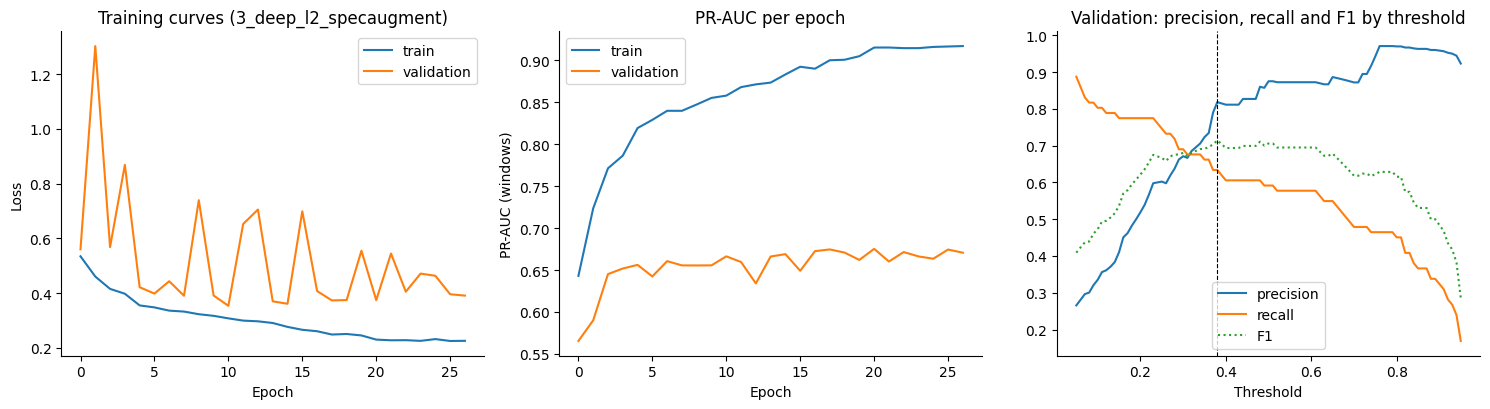

In [30]:
pva, pte = predict(model, Xva), predict(model, Xte)
rva_p, rva_y = per_recording(pva, yva, D["val"]["rec_id"])
rte_p, rte_y = per_recording(pte, yte, D["test"]["rec_id"])

grid = np.linspace(0.05, 0.95, 91)
f1s = [f1_score(rva_y, rva_p >= t) for t in grid]
thr = float(grid[int(np.argmax(f1s))])
print("validation-selected threshold: %.2f (validation recording-level F1 = %.3f)" % (thr, max(f1s)))

fig, axs = plt.subplots(1, 3, figsize=(15, 4.2))
H = hist
axs[0].plot(H["loss"], label="train"); axs[0].plot(H["val_loss"], label="validation"); axs[0].set_xlabel("Epoch"); axs[0].set_ylabel("Loss")
axs[0].set_title(f"Training curves ({best_name})"); axs[0].legend()
axs[1].plot(H["pr_auc"], label="train"); axs[1].plot(H["val_pr_auc"], label="validation"); axs[1].set_xlabel("Epoch"); axs[1].set_ylabel("PR-AUC (windows)")
axs[1].set_title("PR-AUC per epoch"); axs[1].legend()
axs[2].plot(grid, [precision_score(rva_y, rva_p >= t, zero_division=0) for t in grid], label="precision")
axs[2].plot(grid, [recall_score(rva_y, rva_p >= t) for t in grid], label="recall"); axs[2].plot(grid, f1s, label="F1", ls=":")
axs[2].axvline(thr, color="k", ls="--", lw=0.8); axs[2].set_xlabel("Threshold"); axs[2].set_title("Validation: precision, recall and F1 by threshold"); axs[2].legend()
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig6_training_and_threshold.png", dpi=150); plt.show()

**Interpretation.** _To be written after the run._

<!-- interp:8.4 -->

### 8.5 Test Set Results (Used Once)

The selected model and its threshold are now evaluated on the test patients. The table reports **accuracy, loss (binary cross-entropy), precision, recall, F1, ROC-AUC and PR-AUC** per recording, with 95% confidence intervals from resampling **patients** (not recordings), because recordings from one patient are not independent.

In [31]:
rec_df = pd.DataFrame({"rec": D["test"]["rec_id"], "patient": D["test"]["patient_id"], "p": pte, "y": yte}) \
           .groupby("rec").agg(p=("p", "mean"), y=("y", "first"), patient=("patient", "first"))

def rec_metrics(y, p, thr):
    pred = (p >= thr).astype(int)
    return [accuracy_score(y, pred), log_loss(y, np.clip(p, 1e-7, 1 - 1e-7), labels=[0, 1]), precision_score(y, pred, zero_division=0),
            recall_score(y, pred, zero_division=0), f1_score(y, pred, zero_division=0), roc_auc_score(y, p), average_precision_score(y, p)]
names = ["Accuracy", "Loss (log loss)", "Precision (Present)", "Recall (Present)", "F1 (Present)", "ROC-AUC", "PR-AUC"]

groups = {k: v for k, v in rec_df.groupby("patient")}
pats = np.array(list(groups))
rng = np.random.default_rng(SEED)
boot = []
for _ in range(1000):
    d = pd.concat([groups[k] for k in rng.choice(pats, len(pats), replace=True)])
    if d["y"].nunique() < 2:
        continue
    boot.append(rec_metrics(d["y"].values, d["p"].values, thr))
lo, hi = np.percentile(boot, [2.5, 97.5], axis=0)
point = rec_metrics(rte_y, rte_p, thr)
test_table = pd.DataFrame({"metric": names, "value": np.round(point, 3), "ci95_low": np.round(lo, 3), "ci95_high": np.round(hi, 3)})
test_table.to_csv(f"{RES_DIR}/test_metrics.csv", index=False)
print("test patients:", len(pats), "| test recordings:", len(rec_df), "| threshold:", round(thr, 2))
display(test_table)

wm_test = window_metrics(yte, pte, thr)
display(pd.DataFrame([wm_test]).round(3).rename(index={0: "windows (threshold %.2f)" % thr}))
pd.DataFrame([wm_test]).round(4).to_csv(f"{RES_DIR}/test_metrics_window.csv", index=False)

pred = (rte_p >= thr).astype(int)
print(classification_report(rte_y, pred, target_names=["Absent", "Present"], digits=3))

test patients: 132 | test recordings: 459 | threshold: 0.38


,metric,value,ci95_low,ci95_high
0,Accuracy,0.948,0.920,0.972
1,Loss (log loss),0.156,0.112,0.211
2,Precision (Present),0.850,0.716,0.942
3,Recall (Present),0.850,0.736,0.952
4,F1 (Present),0.850,0.747,0.924
5,ROC-AUC,0.960,0.918,0.992
6,PR-AUC,0.923,0.842,0.976


,loss,accuracy,precision,recall,f1,roc_auc,pr_auc
windows (threshold 0.38),0.205,0.91,0.696,0.812,0.75,0.941,0.871


              precision    recall  f1-score   support

      Absent      0.968     0.968     0.968       379
     Present      0.850     0.850     0.850        80

    accuracy                          0.948       459
   macro avg      0.909     0.909     0.909       459
weighted avg      0.948     0.948     0.948       459



**Interpretation.** _To be written after the run._

<!-- interp:8.5 -->

### 8.6 ROC Curve, Precision-Recall Curve and Confusion Matrix (Test)

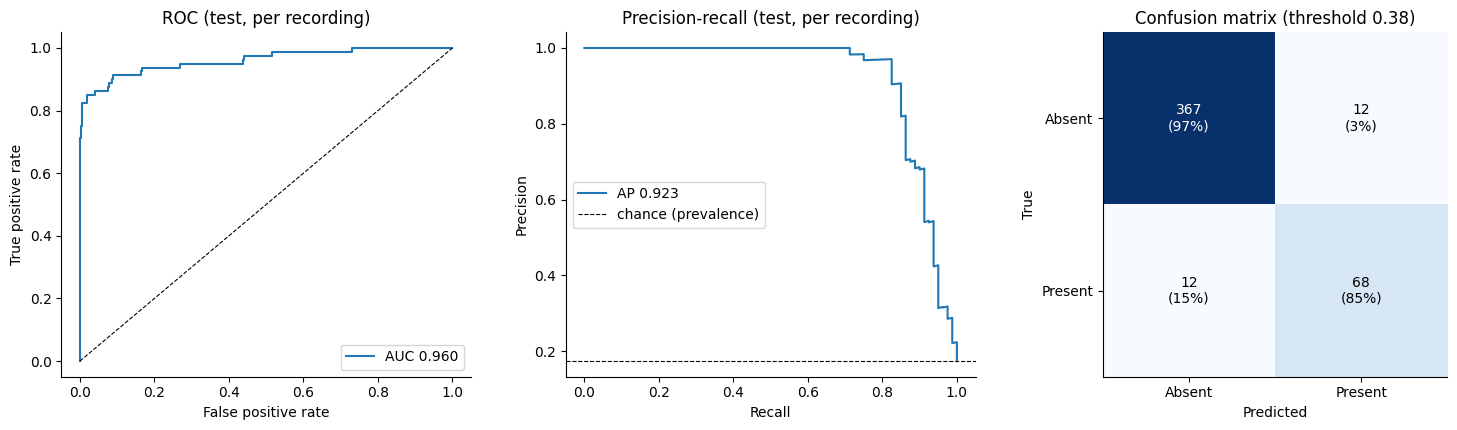

missed murmur recordings: 12 of 80 | false alarms: 12 of 379


In [32]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.4))
fpr, tpr, _ = roc_curve(rte_y, rte_p)
axs[0].plot(fpr, tpr, label=f"AUC {roc_auc_score(rte_y, rte_p):.3f}"); axs[0].plot([0, 1], [0, 1], "k--", lw=0.8)
axs[0].set_xlabel("False positive rate"); axs[0].set_ylabel("True positive rate"); axs[0].set_title("ROC (test, per recording)"); axs[0].legend()
prec, rec_, _ = precision_recall_curve(rte_y, rte_p)
axs[1].plot(rec_, prec, label=f"AP {average_precision_score(rte_y, rte_p):.3f}"); axs[1].axhline(rte_y.mean(), color="k", ls="--", lw=0.8, label="chance (prevalence)")
axs[1].set_xlabel("Recall"); axs[1].set_ylabel("Precision"); axs[1].set_title("Precision-recall (test, per recording)"); axs[1].legend()
cm = confusion_matrix(rte_y, pred)
axs[2].imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        axs[2].text(j, i, f"{cm[i, j]}\n({cm[i, j] / cm[i].sum():.0%})", ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
axs[2].set_xticks([0, 1]); axs[2].set_xticklabels(["Absent", "Present"]); axs[2].set_yticks([0, 1]); axs[2].set_yticklabels(["Absent", "Present"])
axs[2].set_xlabel("Predicted"); axs[2].set_ylabel("True"); axs[2].set_title(f"Confusion matrix (threshold {thr:.2f})")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig5_test_roc_pr_confusion.png", dpi=150); plt.show()
print("missed murmur recordings:", int(cm[1, 0]), "of", int(cm[1].sum()), "| false alarms:", int(cm[0, 1]), "of", int(cm[0].sum()))

**Interpretation.** _To be written after the run._

<!-- interp:8.6 -->

### 8.7 Performance by Auscultation Site

The same test predictions broken down by the site where the recording was made.

,site,recordings,murmur recordings,recall (Present),false alarm rate (Absent)
0,AV,114,16,0.938,0.041
1,MV,119,21,0.857,0.020
2,PV,113,21,0.905,0.043
3,TV,112,21,0.714,0.022


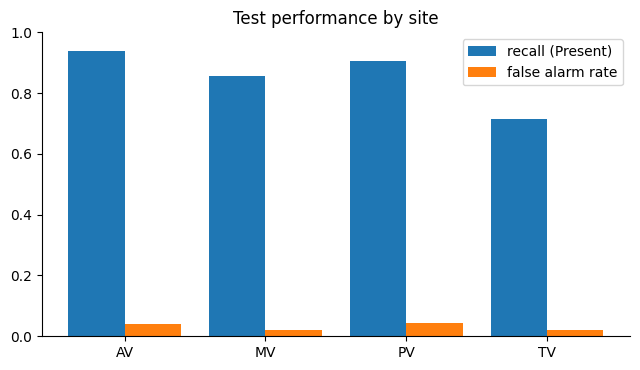

In [33]:
rec_ids_test = np.unique(D["test"]["rec_id"])
bysite = pd.DataFrame({"site": recs.loc[rec_ids_test, "site"].values, "y": rte_y, "pred": pred, "p": rte_p})
rows = []
for s, g in bysite.groupby("site"):
    if len(g) < 20:
        continue
    rows.append({"site": s, "recordings": len(g), "murmur recordings": int(g["y"].sum()),
                 "recall (Present)": round(float(g.loc[g["y"] == 1, "pred"].mean()), 3) if g["y"].sum() else np.nan,
                 "false alarm rate (Absent)": round(float(g.loc[g["y"] == 0, "pred"].mean()), 3)})
site_perf = pd.DataFrame(rows)
display(site_perf)
fig, ax = plt.subplots(figsize=(6.5, 3.8))
x = np.arange(len(site_perf)); ax.bar(x - 0.2, site_perf["recall (Present)"], 0.4, label="recall (Present)"); ax.bar(x + 0.2, site_perf["false alarm rate (Absent)"], 0.4, label="false alarm rate")
ax.set_xticks(x); ax.set_xticklabels(site_perf["site"]); ax.set_ylim(0, 1); ax.legend(); ax.set_title("Test performance by site")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/eval3_by_site.png", dpi=150); plt.show()

**Interpretation.** _To be written after the run._

<!-- interp:8.7 -->

### 8.8 Error Analysis: The Most Confident Mistakes

Averaged spectrograms of the test recordings the model got most wrong: murmur recordings given the lowest murmur probability (missed murmurs) and absent recordings given the highest (false alarms).

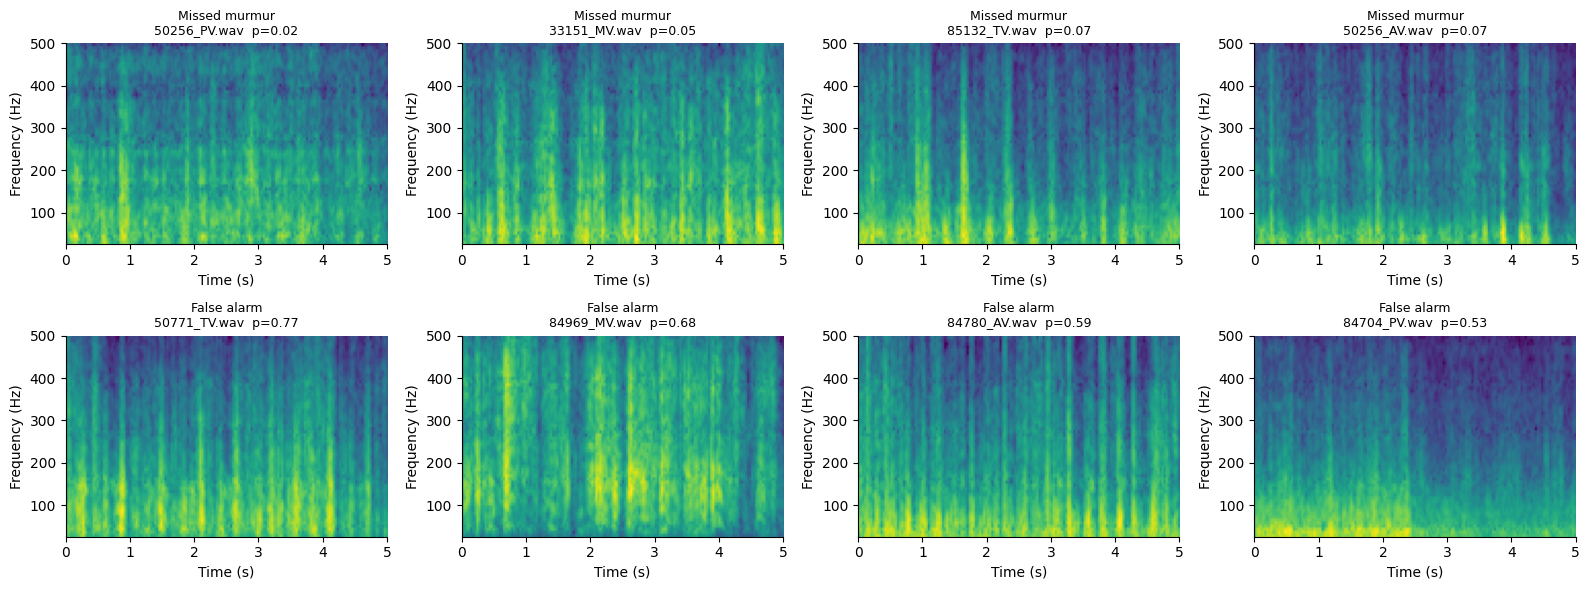

In [34]:
order_idx = np.argsort(rte_p)
fn = [i for i in order_idx if rte_y[i] == 1][:4]                    # lowest probability among true Present
fp = [i for i in order_idx[::-1] if rte_y[i] == 0][:4]              # highest probability among true Absent
fig, axs = plt.subplots(2, 4, figsize=(16, 6))
for row, (idxs, title) in enumerate([(fn, "Missed murmur"), (fp, "False alarm")]):
    for col, i in enumerate(idxs):
        rid = rec_ids_test[i]
        spec = Xte[D["test"]["rec_id"] == rid].astype("float32")[..., 0].mean(0)
        axs[row, col].imshow(spec, origin="lower", aspect="auto", extent=[0, P.WIN_SEC, P.LOW_HZ, P.HIGH_HZ])
        axs[row, col].set_title(f"{title}\n{os.path.basename(recs.loc[rid, 'path'])}  p={rte_p[i]:.2f}", fontsize=9)
        axs[row, col].set_xlabel("Time (s)"); axs[row, col].set_ylabel("Frequency (Hz)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/eval4_error_gallery.png", dpi=150); plt.show()

**Interpretation.** _To be written after the run._

<!-- interp:8.8 -->

## 9. Model Selection and Saving

### 9.1 Saving the Model

The selected model is saved as a single HDF5 file (`.h5`), together with the decision threshold and the preprocessing settings the API needs. A `state.json` file records the model version and threshold, which the API reads at start-up.

In [35]:
h5_path = f"{MODELS_DIR}/murmur_cnn_v1.h5"
model.save(h5_path)
config = {"architecture": best_name, "threshold": thr, "sr": P.SR, "win_sec": P.WIN_SEC, "n_mels": P.N_MELS,
          "input_shape": list(Xtr.shape[1:]), "label_rule_restrict_to_murmur_locations": RESTRICT_TO_MURMUR_LOCATIONS}
json.dump(config, open(f"{MODELS_DIR}/config.json", "w"), indent=2)
json.dump({"version": 1, "model_file": "murmur_cnn_v1.h5", "threshold": thr, "history": []}, open(f"{MODELS_DIR}/state.json", "w"), indent=2)
print("saved", h5_path, "(%.0f KB)" % (os.path.getsize(h5_path) / 1024), "| threshold", round(thr, 2))

saved /kaggle/working/models/murmur_cnn_v1.h5 (1229 KB) | threshold 0.38


### 9.2 Verifying the Saved Model

The file is reloaded and its predictions are compared with the in-memory model on the same test windows. A difference of zero confirms the save and load round trip is lossless.

In [36]:
reloaded = keras.models.load_model(h5_path, compile=False)
a, b = predict(model, Xte[:256]), predict(reloaded, Xte[:256])
print("max absolute difference between in-memory and reloaded predictions:", float(np.abs(a - b).max()))

max absolute difference between in-memory and reloaded predictions: 0.0


### 9.3 Files for the Deployed Application

Small samples and demo recordings are saved for the web application:

- `train_sample.npz`: 400 Absent and 400 Present training windows, used as the base data when retraining.
- `val_sample.npz`: 200 and 200 validation windows, the fixed set that decides whether a retrained model replaces the current one.
- 30 Present and 30 Absent **test** recordings for the demo and the load tests.

Everything is collected in `export/` with the same folder layout as the project repository, and zipped.

In [37]:
EXP = f"{WORK}/export"
shutil.rmtree(EXP, ignore_errors=True)
for d in ["models", "data/train", "data/test/present", "data/test/absent", "ui/assets/figures", "ui/assets/results"]:
    os.makedirs(f"{EXP}/{d}")
shutil.copy(h5_path, f"{EXP}/models/"); shutil.copy(f"{MODELS_DIR}/config.json", f"{EXP}/models/"); shutil.copy(f"{MODELS_DIR}/state.json", f"{EXP}/models/")
shutil.copy(f"{MODELS_DIR}/state.json", f"{EXP}/models/state.v1.json")

rs_ = np.random.default_rng(SEED)
def balanced_sample(X, y, n):
    idx = np.concatenate([rs_.choice(np.where(y == c)[0], min(n, int((y == c).sum())), replace=False) for c in (0., 1.)])
    return X[idx], y[idx]
train_sample = balanced_sample(Xtr, ytr, 400); val_sample = balanced_sample(Xva, yva, 200)
np.savez_compressed(f"{EXP}/data/train/train_sample.npz", X=train_sample[0], y=train_sample[1])
np.savez_compressed(f"{EXP}/data/train/val_sample.npz", X=val_sample[0], y=val_sample[1])

test_recs = recs[recs.split == "test"]
demo_ids = {}
for lab_, name in [(1, "present"), (0, "absent")]:
    pool = test_recs[test_recs.label == lab_]
    chosen = pool.sample(min(30, len(pool)), random_state=SEED)
    demo_ids[name] = list(chosen.index)
    for _, r in chosen.iterrows():
        shutil.copy(r.path, f"{EXP}/data/test/{name}/{os.path.basename(r.path)}")

recs.drop(columns=["path"]).to_csv(f"{EXP}/ui/assets/recordings.csv", index=False)
for f in os.listdir(FIG_DIR): shutil.copy(f"{FIG_DIR}/{f}", f"{EXP}/ui/assets/figures/{f}")
for f in os.listdir(RES_DIR): shutil.copy(f"{RES_DIR}/{f}", f"{EXP}/ui/assets/results/{f}")
shutil.make_archive(f"{WORK}/export", "zip", EXP)
print("export.zip: %.1f MB" % (os.path.getsize(f"{WORK}/export.zip") / 1e6), "| demo recordings:", {k: len(v) for k, v in demo_ids.items()})

export.zip: 33.4 MB | demo recordings: {'present': 30, 'absent': 30}


## 10. Prediction Function (Demo)

### 10.1 A Single-Recording Prediction Function

`predict_recording` takes a path to a .wav file and a trained model. It runs the same preprocessing as training, predicts every window, averages the window probabilities and applies the threshold. This is the same logic as the prediction API (`src/prediction.py`).

In [38]:
def predict_recording(path, model, threshold):
    X = P.wav_to_features(path, max_windows=MAX_WINDOWS_PER_REC)
    if len(X) == 0:
        raise ValueError(f"Recording is shorter than {P.MIN_SEC} s")
    probs = model(X.astype("float32"), training=False).numpy().ravel()
    p = float(probs.mean())
    return {"label": "Present" if p >= threshold else "Absent", "probability": p, "window_probabilities": probs, "spectrogram": X[0, ..., 0]}

### 10.2 Demonstration on Six Test Recordings

Three murmur-present and three murmur-absent test recordings are picked at random (fixed seed) and passed to the function as .wav files, as an uploaded file would arrive. The function is not given the label. The result is compared with the dataset label afterwards, and the mistakes, if any, are shown as they are.

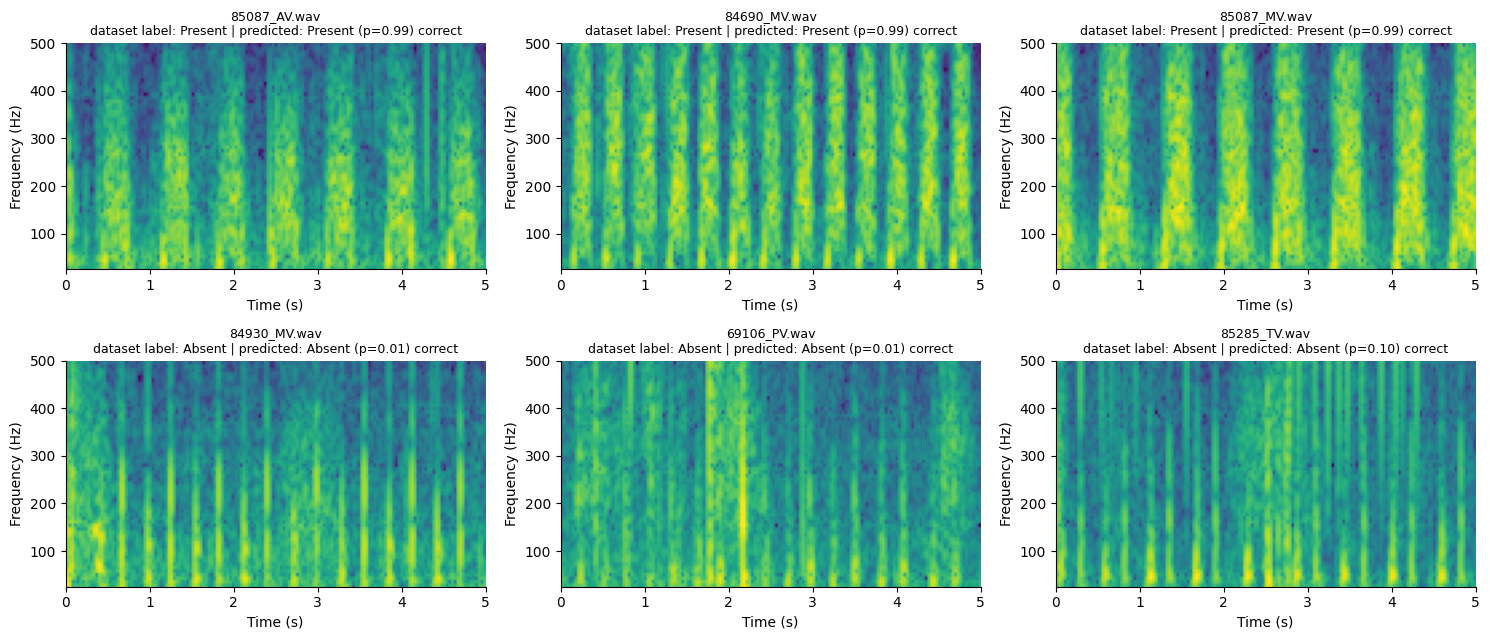

6 of 6 demo recordings predicted correctly


In [39]:
rs2 = np.random.default_rng(SEED + 1)
picks = [("Present", int(i)) for i in rs2.choice(demo_ids["present"], 3, replace=False)] + \
        [("Absent", int(i)) for i in rs2.choice(demo_ids["absent"], 3, replace=False)]
fig, axs = plt.subplots(2, 3, figsize=(15, 6.5))
outcomes = []
for ax, (truth, rid) in zip(axs.ravel(), picks):
    out = predict_recording(recs.loc[rid, "path"], model, thr)
    ok = out["label"] == truth
    outcomes.append(ok)
    ax.imshow(out["spectrogram"], origin="lower", aspect="auto", extent=[0, P.WIN_SEC, P.LOW_HZ, P.HIGH_HZ])
    ax.set_title(f"{os.path.basename(recs.loc[rid, 'path'])}\ndataset label: {truth} | predicted: {out['label']} (p={out['probability']:.2f}) {'correct' if ok else 'WRONG'}", fontsize=9)
    ax.set_xlabel("Time (s)"); ax.set_ylabel("Frequency (Hz)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/demo_predictions.png", dpi=150); plt.show()
print(f"{sum(outcomes)} of {len(outcomes)} demo recordings predicted correctly")

**Interpretation.** _To be written after the run._

<!-- interp:10.2 -->

## 11. Retraining Demonstration

### 11.1 A Retraining Function

The deployed application retrains when a user uploads new labelled recordings. `retrain_model` shows the same procedure offline:

1. Reload the saved model (the custom model acts as the pre-trained starting point).
2. Combine the new windows with the base training sample and recompute class weights.
3. Fine-tune for a few epochs at a low learning rate (1e-4).
4. Score the old and new model on the same fixed validation sample.
5. **Promote** the new model only if its PR-AUC is within a tolerance (0.01) of the old one, so a bad batch cannot silently replace a good model.

In [40]:
def eval_windows(m, X, y, threshold):
    p = predict(m, X); pr = (p >= threshold).astype(int)
    return {"roc_auc": roc_auc_score(y, p), "pr_auc": average_precision_score(y, p), "precision": precision_score(y, pr, zero_division=0),
            "recall": recall_score(y, pr, zero_division=0), "f1": f1_score(y, pr, zero_division=0)}

def retrain_model(model_path, X_new, y_new, X_base, y_base, X_val, y_val, threshold, epochs=5, lr=1e-4, tolerance=0.01):
    tf.keras.utils.set_random_seed(SEED)
    m = keras.models.load_model(model_path, compile=False)
    compile_model(m, lr)
    before = eval_windows(m, X_val, y_val, threshold)
    X, y = np.concatenate([X_base, X_new]), np.concatenate([y_base, y_new])
    order = np.random.default_rng(SEED).permutation(len(X)); X, y = X[order], y[order]
    cw_ = compute_class_weight("balanced", classes=np.array([0., 1.]), y=y)
    m.fit(make_ds(X, y, shuffle=True), epochs=epochs, class_weight={0: float(cw_[0]), 1: float(cw_[1])}, verbose=2)
    after = eval_windows(m, X_val, y_val, threshold)
    promoted = after["pr_auc"] >= before["pr_auc"] - tolerance
    return m, before, after, promoted

### 11.2 Demonstration

The 60 demo recordings (30 Present, 30 Absent) play the role of newly uploaded data. Their windows are taken from the processed test arrays. The base data and the validation set are the small samples that ship with the deployed application.

These recordings come from the **test patients**, so after this step the test set is no longer untouched for the retrained model. The test results in Section 8 belong to the model **before** retraining.

In [41]:
new_mask = np.isin(D["test"]["rec_id"], demo_ids["present"] + demo_ids["absent"])
X_new, y_new = Xte[new_mask], yte[new_mask]
print("new data: %d windows from %d recordings (%d murmur windows)" % (len(X_new), len(demo_ids["present"]) + len(demo_ids["absent"]), int(y_new.sum())))

m_new, before, after, promoted = retrain_model(h5_path, X_new, y_new, train_sample[0], train_sample[1], val_sample[0], val_sample[1], thr)
display(pd.DataFrame({"before": before, "after": after}).T.round(3))
print("decision:", "promote the retrained model" if promoted else "keep the current model", "(tolerance 0.01 on PR-AUC)")
m_new.save(f"{MODELS_DIR}/murmur_cnn_retrained_demo.h5")
print("saved", f"{MODELS_DIR}/murmur_cnn_retrained_demo.h5", "(kept separate from the exported v1 model)")

new data: 284 windows from 60 recordings (130 murmur windows)
Epoch 1/5


E0000 00:00:1795366967.538821     191 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


17/17 - 16s - 942ms/step - auc: 0.9667 - loss: 0.3153 - pr_auc: 0.9687
Epoch 2/5
17/17 - 0s - 22ms/step - auc: 0.9674 - loss: 0.2583 - pr_auc: 0.9699
Epoch 3/5
17/17 - 0s - 18ms/step - auc: 0.9760 - loss: 0.2210 - pr_auc: 0.9771
Epoch 4/5
17/17 - 0s - 19ms/step - auc: 0.9795 - loss: 0.2075 - pr_auc: 0.9814
Epoch 5/5
17/17 - 0s - 19ms/step - auc: 0.9789 - loss: 0.2114 - pr_auc: 0.9802


,roc_auc,pr_auc,precision,recall,f1
before,0.834,0.861,0.851,0.600,0.704
after,0.850,0.870,0.661,0.895,0.760


decision: promote the retrained model (tolerance 0.01 on PR-AUC)
saved /kaggle/working/models/murmur_cnn_retrained_demo.h5 (kept separate from the exported v1 model)


**Interpretation.** _To be written after the run._

<!-- interp:11.2 -->

## 12. Conclusions

### 12.1 Summary of Findings

_To be written after the run._

<!-- interp:12.1 -->

### 12.2 Limitations

_To be written after the run._

<!-- interp:12.2 -->

### 12.3 Future Work

_To be written after the run._

<!-- interp:12.3 -->